<div style="background:#1F3864;color:white;padding:14px 18px;border-radius:6px"><b>INTERNATIONAL UNIVERSITY – VNU-HCMC · SCHOOL OF COMPUTER SCIENCE AND ENGINEERING</b><br>IT171IU · Statistical Learning</div>

# Lab 2: Linear Regression

*Simple and multiple linear regression with statsmodels and ISLP: estimation, inference, prediction, diagnostics, interactions, non-linear terms and qualitative predictors*

**Chapter:** ISLP Chapter 3 · **Duration:** 150 minutes (3 periods) · **Runs on:** Google Colab (recommended), Jupyter Notebook / JupyterLab, VS Code, PyCharm

**How to use this notebook:** first *File → Save a copy in Drive*. Run the **Setup** cell, then read each text cell and run the code cells in order with **Shift + Enter**. Write your solutions in the cells marked ✍️ and answer the questions in the text cells.

> **Legend:** black = original ISLP lab content (re-formatted) · <span style="color:red">red = content added for IT171IU (theory, worked examples, exercises, setup & submission guide)</span>

In [1]:
from sympy.parsing.sympy_parser import transformations

# Student information – fill in and run this cell first
STUDENT_NAME = "Mai Dong Huy"
STUDENT_ID   = "ITDSIU24019"
CLASS_GROUP  = "IT171IU – Lab Group 01"
print(f"Lab 2 | {STUDENT_NAME} | {STUDENT_ID} | {CLASS_GROUP}")

Lab 2 | Mai Dong Huy | ITDSIU24019 | IT171IU – Lab Group 01


# <span style="color:red">1. Objectives</span>

<span style="color:red">After this lab you will be able to:</span>

- <span style="color:red">Fit simple and multiple linear regression models with `statsmodels` (`sm.OLS`) and build design matrices with `ISLP.models.ModelSpec`.</span>
- <span style="color:red">Interpret coefficients, standard errors, $t$-statistics, $p$-values, confidence intervals, $R^2$, RSE and the $F$-statistic.</span>
- <span style="color:red">Distinguish **confidence intervals** for the mean response from **prediction intervals** for a new observation.</span>
- <span style="color:red">Diagnose problems with residual plots, leverage statistics, outliers and variance inflation factors (VIF).</span>
- <span style="color:red">Add interaction terms, polynomial terms and transformations, and compare nested models with `anova_lm()`.</span>
- <span style="color:red">Encode qualitative predictors with dummy variables and interpret their coefficients.</span>

> 📌 <span style="color:red">**Note** — **Lab plan – 150 minutes (3 periods)**</span>
>
> | <span style="color:red">Time</span> | <span style="color:red">Activity</span> |
> |---|---|
> | <span style="color:red">0 – 20 min</span> | <span style="color:red">Theory review: least squares, standard errors, t- and F-tests, R², diagnostics (Section 2)</span> |
> | <span style="color:red">20 – 75 min</span> | <span style="color:red">Guided lab: simple and multiple regression on Boston, interactions, polynomials, qualitative predictors (Section 3)</span> |
> | <span style="color:red">75 – 90 min</span> | <span style="color:red">Extra worked examples: least squares "by hand", transformations and diagnostics</span> |
> | <span style="color:red">90 – 140 min</span> | <span style="color:red">Exercises 1 – 7 (Section 4); challenge exercises 8 – 9 if time allows</span> |
> | <span style="color:red">140 – 150 min</span> | <span style="color:red">Run all cells, save and submit through the Google Form (Section 5)</span> |

# <span style="color:red">2. Theory</span>

## <span style="color:red">2.1 Simple linear regression</span>

<span style="color:red">We assume an approximately linear relationship between a predictor $X$ and a response $Y$:</span>

$$\color{red}{Y = \beta_0 + \beta_1 X + \varepsilon .}$$

<span style="color:red">The **least-squares** estimates minimise the residual sum of squares $\mathrm{RSS} = \sum_{i=1}^n (y_i - \hat\beta_0 - \hat\beta_1 x_i)^2$:</span>

$$\color{red}{\hat\beta_1 = \frac{\sum_{i=1}^n (x_i-\bar x)(y_i-\bar y)}{\sum_{i=1}^n (x_i-\bar x)^2}, \qquad \hat\beta_0 = \bar y - \hat\beta_1 \bar x .}$$

<span style="color:red">The **standard error** $\mathrm{SE}(\hat\beta_1)$ measures how much $\hat\beta_1$ would vary over repeated samples. An approximate 95% confidence interval is $\hat\beta_1 \pm 2\,\mathrm{SE}(\hat\beta_1)$. To test $H_0:\beta_1 = 0$ we use</span>

$$\color{red}{t = \frac{\hat\beta_1 - 0}{\mathrm{SE}(\hat\beta_1)},}$$

<span style="color:red">which has a $t$-distribution with $n-2$ degrees of freedom under $H_0$; a small $p$-value means we reject $H_0$.</span>

## <span style="color:red">2.2 Assessing the fit</span>

- <span style="color:red">**Residual standard error:** $\mathrm{RSE} = \sqrt{\mathrm{RSS}/(n-2)}$ – the typical size of a prediction error, in the units of $Y$.</span>
- <span style="color:red">**Coefficient of determination:** $R^2 = 1 - \mathrm{RSS}/\mathrm{TSS}$ with $\mathrm{TSS} = \sum_i (y_i - \bar y)^2$ – the proportion of variability in $Y$ explained by the model (between 0 and 1). In simple regression $R^2 = \mathrm{Cor}(X,Y)^2$.</span>

## <span style="color:red">2.3 Multiple linear regression</span>

<span style="color:red">With $p$ predictors, $Y = \beta_0 + \beta_1 X_1 + \dots + \beta_p X_p + \varepsilon$. The coefficient $\beta_j$ is the average change in $Y$ for a one-unit increase in $X_j$ **holding all other predictors fixed**. To test whether *any* predictor is useful ($H_0: \beta_1 = \dots = \beta_p = 0$) we use the **F-statistic**</span>

$$\color{red}{F = \frac{(\mathrm{TSS}-\mathrm{RSS})/p}{\mathrm{RSS}/(n-p-1)} .}$$

<span style="color:red">To compare a smaller model with $q$ coefficients set to zero against the full model, `anova_lm()` computes the partial F-statistic $\frac{(\mathrm{RSS}_0-\mathrm{RSS})/q}{\mathrm{RSS}/(n-p-1)}$.</span>

<span style="color:red">In matrix form the estimates are $\hat\beta = (X^\top X)^{-1} X^\top y$, where the first column of the design matrix $X$ is the intercept column of ones.</span>

## <span style="color:red">2.4 Extending the linear model</span>

| <span style="color:red">Extension</span> | <span style="color:red">Example term</span> | <span style="color:red">Remark</span> |
|---|---|---|
| <span style="color:red">Qualitative predictor</span> | <span style="color:red">`ShelveLoc` → dummies `ShelveLoc[Good]`, `ShelveLoc[Medium]`</span> | <span style="color:red">coefficients are differences from the *baseline* level</span> |
| <span style="color:red">Interaction</span> | <span style="color:red">`('lstat', 'age')` → $\beta_3\,\mathrm{lstat}\times\mathrm{age}$</span> | <span style="color:red">the effect of one predictor depends on the other; keep the main effects (*hierarchical principle*)</span> |
| <span style="color:red">Polynomial</span> | <span style="color:red">`poly('lstat', degree=2)`</span> | <span style="color:red">still a *linear* model in the coefficients</span> |
| <span style="color:red">Transformation</span> | <span style="color:red">$\log(X)$, $\sqrt{X}$, $\log(Y)$</span> | <span style="color:red">may fix non-linearity or non-constant variance</span> |

## <span style="color:red">2.5 Potential problems and diagnostics</span>

| <span style="color:red">Problem</span> | <span style="color:red">How to detect</span> | <span style="color:red">Typical remedy</span> |
|---|---|---|
| <span style="color:red">Non-linearity</span> | <span style="color:red">pattern in the plot of residuals vs fitted values</span> | <span style="color:red">add polynomial terms / transform $X$</span> |
| <span style="color:red">Correlated errors</span> | <span style="color:red">residuals tracking over time</span> | <span style="color:red">time-series models</span> |
| <span style="color:red">Non-constant variance</span> | <span style="color:red">funnel shape in the residual plot</span> | <span style="color:red">transform $Y$ ($\log Y$, $\sqrt{Y}$), weighted least squares</span> |
| <span style="color:red">Outliers</span> | <span style="color:red">studentized residuals with $</span> | <span style="color:red">r_i</span> | <span style="color:red">> 3$</span> | <span style="color:red">check the data; robust methods</span> |
| <span style="color:red">High leverage points</span> | <span style="color:red">leverage $h_i$ much larger than $(p+1)/n$</span> | <span style="color:red">check the data; refit without them</span> |
| <span style="color:red">Collinearity</span> | <span style="color:red">$\mathrm{VIF}(\hat\beta_j) = 1/(1-R^2_{X_j\mid X_{-j}}) > 5$–$10$</span> | <span style="color:red">drop or combine predictors, regularisation (Lab 5)</span> |

<span style="color:red">**Confidence vs prediction interval.** A confidence interval quantifies the uncertainty about the *average* response $f(x_0)$; a prediction interval for an individual $y_0 = f(x_0) + \varepsilon$ is always **wider** because it also includes the irreducible error $\varepsilon$.</span>

# 3. Instructions and Worked Examples

<span style="color:red">Work through this section **in order**: read each explanation, *predict* what a cell will print, then run it. The black text and code are the original ISLP Chapter 3 lab; red notes, checkpoints and extra worked examples were added for IT171IU.</span>

### <span style="color:red">Setup cell</span>

In [2]:
# [ADDED]
# 0. Setup – run this cell first (installs missing packages and fetches data files).
# On Google Colab the first run takes about 1 minute. If Colab asks you to
# "Restart session", accept, then run this cell once more.
import sys, os, subprocess, importlib.util, urllib.request

def ensure(module, pip_name=None):
    """pip-install a package only if it cannot be imported yet."""
    if importlib.util.find_spec(module) is None:
        print(f"Installing {pip_name or module} ...")
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", pip_name or module], check=True)

ensure("ISLP", "ISLP")

print("Setup complete – Python", sys.version.split()[0])

Setup complete – Python 3.13.14


In [3]:
# [ADDED] helper for the additional datasets
# Loader for the additional datasets of this course (folder "additional-data/").
# If the CSV file is not found next to the notebook, it is rebuilt from its public source,
# so the notebook also works on Colab without uploading anything.
import pandas as pd
def load_extra(name):
    for folder in ["additional-data", "../additional-data", "/content/additional-data",
                   "/content/drive/MyDrive/additional-data"]:
        path = os.path.join(folder, name + ".csv")
        if os.path.exists(path):
            return pd.read_csv(path)
    from sklearn import datasets as skd
    if name == "diabetes":
        d = skd.load_diabetes(as_frame=True, scaled=False); df = d.frame.rename(columns={"target": "progression"})
    elif name == "breast_cancer":
        d = skd.load_breast_cancer(as_frame=True); df = d.frame.copy()
        df["diagnosis"] = pd.Categorical.from_codes(d.target, ["malignant", "benign"]); df = df.drop(columns="target")
    elif name == "wine":
        d = skd.load_wine(as_frame=True); df = d.frame.rename(columns={"target": "cultivar"})
    elif name == "digits":
        d = skd.load_digits(as_frame=True); df = d.frame.rename(columns={"target": "digit"})
    elif name == "rossi":
        from lifelines.datasets import load_rossi; df = load_rossi()
    else:
        raise ValueError(f"unknown dataset {name!r}")
    return df

## 3.1 Importing packages
We import our standard libraries at this top
level.

In [4]:
import numpy as np
import pandas as pd
from matplotlib.pyplot import subplots

### New imports
Throughout this lab we will introduce new functions and libraries. However,
we will import them here to emphasize these are the new
code objects in this lab. Keeping imports near the top
of a notebook makes the code more readable, since scanning the first few
lines tells us what libraries are used.

In [5]:
import statsmodels.api as sm

 We will provide relevant details about the
functions below as they are needed.

Besides importing whole modules, it is also possible
to import only a few items from a given module. This
will help keep the  *namespace* clean.
We will use a few specific objects from the `statsmodels` package
which we import here.

In [6]:
from statsmodels.stats.outliers_influence \
     import variance_inflation_factor as VIF
from statsmodels.stats.anova import anova_lm

As one of the import statements above is quite a long line, we inserted a line break `\` to
ease readability.

We will also use some functions written for the labs in this book in the `ISLP`
package.

In [7]:
from ISLP import load_data
from ISLP.models import (ModelSpec as MS,
                         summarize,
                         poly)

> 📌 <span style="color:red">**Note** — **ISLP helpers used in this lab**</span>
>
> <span style="color:red">`load_data()` returns a data set as a pandas data frame; `ModelSpec` (imported as `MS`) builds design matrices (intercept, dummies, interactions, polynomials); `summarize()` prints a compact coefficient table; `poly()` creates orthogonal polynomial columns.</span>

### Inspecting Objects and Namespaces
The
function  `dir()`
provides a list of
objects in a namespace.

In [8]:
dir()

['CLASS_GROUP',
 'In',
 'MS',
 'Out',
 'STUDENT_ID',
 'STUDENT_NAME',
 'VIF',
 '_',
 '__',
 '___',
 '__builtin__',
 '__builtins__',
 '__doc__',
 '__loader__',
 '__name__',
 '__package__',
 '__spec__',
 '_dh',
 '_i',
 '_i1',
 '_i2',
 '_i3',
 '_i4',
 '_i5',
 '_i6',
 '_i7',
 '_i8',
 '_ih',
 '_ii',
 '_iii',
 '_oh',
 'anova_lm',
 'ensure',
 'exit',
 'get_ipython',
 'importlib',
 'load_data',
 'load_extra',
 'np',
 'open',
 'os',
 'pd',
 'poly',
 'quit',
 'sm',
 'subplots',
 'subprocess',
 'summarize',
 'sys',
 'transformations',
 'urllib']

 This shows you everything that `Python` can find at the top level.
There are certain objects like `__builtins__` that contain references to built-in
functions like `print()`.

Every python object has its own notion of
namespace, also accessible with `dir()`. This will include
both the attributes of the object
as well as any methods associated with it. For instance, we see `'sum'` in the listing for an
array.

In [9]:
A = np.array([3,5,11])
dir(A)

['T',
 '__abs__',
 '__add__',
 '__and__',
 '__array__',
 '__array_finalize__',
 '__array_function__',
 '__array_interface__',
 '__array_namespace__',
 '__array_priority__',
 '__array_struct__',
 '__array_ufunc__',
 '__array_wrap__',
 '__bool__',
 '__buffer__',
 '__class__',
 '__class_getitem__',
 '__complex__',
 '__contains__',
 '__copy__',
 '__deepcopy__',
 '__delattr__',
 '__delitem__',
 '__dir__',
 '__divmod__',
 '__dlpack__',
 '__dlpack_device__',
 '__doc__',
 '__eq__',
 '__float__',
 '__floordiv__',
 '__format__',
 '__ge__',
 '__getattribute__',
 '__getitem__',
 '__getstate__',
 '__gt__',
 '__hash__',
 '__iadd__',
 '__iand__',
 '__ifloordiv__',
 '__ilshift__',
 '__imatmul__',
 '__imod__',
 '__imul__',
 '__index__',
 '__init__',
 '__init_subclass__',
 '__int__',
 '__invert__',
 '__ior__',
 '__ipow__',
 '__irshift__',
 '__isub__',
 '__iter__',
 '__itruediv__',
 '__ixor__',
 '__le__',
 '__len__',
 '__lshift__',
 '__lt__',
 '__matmul__',
 '__mod__',
 '__mul__',
 '__ne__',
 '__neg__',


 This indicates that the object `A.sum` exists. In this case it is a method
that can be used to compute the sum of the array `A` as can be seen by typing `A.sum?`.

In [10]:
A.sum()

np.int64(19)

## 3.2 Simple Linear Regression
In this section we will  construct model
matrices (also called design matrices) using the `ModelSpec()`  transform from `ISLP.models`.

We  will use the `Boston` housing data set, which is contained in the `ISLP` package.  The `Boston` dataset records  `medv`  (median house value) for $506$ neighborhoods
around Boston.  We will build a regression model to predict  `medv`  using $13$
predictors such as  `rm`  (average number of rooms per house),
 `age`  (proportion of owner-occupied units built prior to 1940), and  `lstat`  (percent of
households with low socioeconomic status).  We will use `statsmodels` for this
task, a `Python` package that implements several commonly used
regression methods.

We have included a simple loading function `load_data()` in the
`ISLP` package:

In [11]:
Boston = load_data("Boston")
Boston.columns


Index(['crim', 'zn', 'indus', 'chas', 'nox', 'rm', 'age', 'dis', 'rad', 'tax',
       'ptratio', 'lstat', 'medv'],
      dtype='object')

Type `Boston?` to find out more about these data.

We start by using the `sm.OLS()`  function to fit a
simple linear regression model.  Our response will be
 `medv`  and  `lstat`  will be the single predictor.
For this model, we can create the model matrix by hand.

In [12]:
X = pd.DataFrame({'intercept': np.ones(Boston.shape[0]),
                  'lstat': Boston['lstat']})
X[:4]

,intercept,lstat
0,1.0,4.98
1,1.0,9.14
2,1.0,4.03
3,1.0,2.94


We extract the response, and fit the model.

In [13]:
y = Boston['medv']
model = sm.OLS(y, X)
results = model.fit()

Note that `sm.OLS()` does
not fit the model; it specifies the model, and then `model.fit()` does the actual fitting.

Our `ISLP` function `summarize()` produces a simple table of the parameter estimates,
their standard errors, t-statistics and p-values.
The function takes a single argument, such as the object `results`
returned here by the `fit`
method, and returns such a summary.

In [14]:
summarize(results)

,coef,std err,t,P>|t|
intercept,34.5538,0.563,61.415,0.0
lstat,-0.9500,0.039,-24.528,0.0


In [15]:
results.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                   medv   R-squared:                       0.544
Model:                            OLS   Adj. R-squared:                  0.543
Method:                 Least Squares   F-statistic:                     601.6
Date:                Mon, 12 Oct 2026   Prob (F-statistic):           5.08e-88
Time:                        21:35:22   Log-Likelihood:                -1641.5
No. Observations:                 506   AIC:                             3287.
Df Residuals:                     504   BIC:                             3295.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
intercept     34.5538      0.563     61.415      0.000      33.448      35.659
lstat         -0.9500      0.039    -24.528      0.000      -1.026      -0.874
==============================================================================
Omnibus:                      137.043   Durbin-Watson:                   0.892
Prob(Omnibus):                  0.000   Jarque-Bera (JB):              291.373
Skew:                           1.453   Prob(JB):                     5.36e-64
Kurtosis:                       5.319   Cond. No.                         29.7
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

Before we describe other methods for working with fitted models, we outline a more useful and general framework for constructing a model matrix~`X`.
### Using Transformations: Fit and Transform
Our model above has a single predictor, and constructing `X` was straightforward.
In practice  we often fit models with more than one predictor, typically selected from an array or data frame.
We may wish to introduce transformations to the variables before fitting the model, specify interactions between variables, and expand some particular variables into sets of variables (e.g. polynomials).
The `sklearn`  package has a particular notion
for this type of task: a *transform*. A transform is an object
that is created with some parameters as arguments. The
object has two main methods: `fit()` and `transform()`.

We provide a general approach for specifying models and constructing
the model matrix through the transform `ModelSpec()` in the `ISLP` library.
`ModelSpec()`
(renamed `MS()` in the preamble) creates a
transform object, and then a pair of methods
`transform()` and `fit()` are used to construct a
corresponding model matrix.

We first describe this process for our simple regression model  using a single predictor `lstat` in
the `Boston` data frame, but will use it repeatedly in more
complex tasks in this and other labs in this book.
In our case the transform is created by the expression
`design = MS(['lstat'])`.

The `fit()`  method takes the original array and may do some
initial computations on it, as specified in the transform object.
For example, it may compute means and standard deviations for centering and scaling.
The `transform()`
method applies the fitted transformation to the array of data, and produces the model matrix.

In [16]:
design = MS(['lstat'])
design = design.fit(Boston)
X = design.transform(Boston)
X[:4]

,intercept,lstat
0,1.0,4.98
1,1.0,9.14
2,1.0,4.03
3,1.0,2.94


In this simple case, the `fit()`  method does very little; it simply checks that the variable `'lstat'` specified in `design` exists in `Boston`. Then `transform()` constructs the model matrix with two columns: an `intercept` and the variable `lstat`.

These two operations can be  combined with the
`fit_transform()`  method.

In [17]:
design = MS(['lstat'])
X = design.fit_transform(Boston)
X[:4]

,intercept,lstat
0,1.0,4.98
1,1.0,9.14
2,1.0,4.03
3,1.0,2.94


Note that, as in the previous code chunk when the two steps were done separately, the `design` object is changed as a result of the `fit()` operation. The power of this pipeline will become clearer when we fit more complex models that involve interactions and transformations.

Let's return to our fitted regression model.
The object
`results` has several methods that can be used for inference.
We already presented a function `summarize()` for showing the essentials of the fit.
For a full and somewhat exhaustive summary of the fit, we can use the `summary()`
method.

In [18]:
results.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                   medv   R-squared:                       0.544
Model:                            OLS   Adj. R-squared:                  0.543
Method:                 Least Squares   F-statistic:                     601.6
Date:                Mon, 12 Oct 2026   Prob (F-statistic):           5.08e-88
Time:                        21:35:22   Log-Likelihood:                -1641.5
No. Observations:                 506   AIC:                             3287.
Df Residuals:                     504   BIC:                             3295.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
intercept     34.5538      0.563     61.415      0.000      33.448      35.659
lstat         -0.9500      0.039    -24.528      0.000      -1.026      -0.874
==============================================================================
Omnibus:                      137.043   Durbin-Watson:                   0.892
Prob(Omnibus):                  0.000   Jarque-Bera (JB):              291.373
Skew:                           1.453   Prob(JB):                     5.36e-64
Kurtosis:                       5.319   Cond. No.                         29.7
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

The fitted coefficients can also be retrieved as the
`params` attribute of `results`.

In [19]:
results.params

intercept    34.553841
lstat        -0.950049
dtype: float64

The `get_prediction()`  method can be used to obtain predictions, and produce confidence intervals and
prediction intervals for the prediction of  `medv`  for  given values of  `lstat`.

We first create a new data frame, in this case containing only the variable `lstat`, with the values for this variable at which we wish to make predictions.
We then use the `transform()` method of `design` to create the corresponding model matrix.

In [20]:
new_df = pd.DataFrame({'lstat':[5, 10, 15]})
newX = design.transform(new_df)
newX

,intercept,lstat
0,1.0,5
1,1.0,10
2,1.0,15


Next we compute the predictions at `newX`, and view them by extracting the `predicted_mean` attribute.

In [21]:
new_predictions = results.get_prediction(newX);
new_predictions.predicted_mean

array([29.80359411, 25.05334734, 20.30310057])

We can produce confidence intervals for the predicted values.

In [22]:
new_predictions.conf_int(alpha=0.05)

array([[29.00741194, 30.59977628],
       [24.47413202, 25.63256267],
       [19.73158815, 20.87461299]])

Prediction intervals are computed by setting `obs=True`:

In [23]:
new_predictions.conf_int(obs=True, alpha=0.05)

array([[17.56567478, 42.04151344],
       [12.82762635, 37.27906833],
       [ 8.0777421 , 32.52845905]])

 For instance, the 95% confidence interval associated with an
 `lstat`  value of 10 is (24.47, 25.63), and the 95% prediction
interval is (12.82, 37.28).  As expected, the confidence and
prediction intervals are centered around the same point (a predicted
value of 25.05 for  `medv`  when  `lstat`  equals
10), but the latter are substantially wider.

Next we will plot  `medv`  and  `lstat`
using `DataFrame.plot.scatter()`, \definelongblankMR{plot.scatter()}{plot.slashslashscatter()}
and wish to
add the regression line to the resulting plot.

### Defining Functions
While there is a function
within the `ISLP` package that adds a line to an existing plot, we take this opportunity
to define our first function to do so.

In [24]:
def abline(ax, b, m):
    "Add a line with slope m and intercept b to ax"
    xlim = ax.get_xlim()
    ylim = [m * xlim[0] + b, m * xlim[1] + b]
    ax.plot(xlim, ylim)

 A few things are illustrated above. First we see the syntax for defining a function:
`def funcname(...)`. The function has arguments `ax, b, m`
where `ax` is an axis object for an existing plot, `b` is the intercept and
`m` is the slope of the desired line. Other plotting  options can be passed on to
`ax.plot` by including additional optional arguments as follows:

In [25]:
def abline(ax, b, m, *args, **kwargs):
    "Add a line with slope m and intercept b to ax"
    xlim = ax.get_xlim()
    ylim = [m * xlim[0] + b, m * xlim[1] + b]
    ax.plot(xlim, ylim, *args, **kwargs)

The addition of `*args` allows any number of
non-named arguments to `abline`, while `**kwargs` allows any
number of named arguments (such as `linewidth=3`) to `abline`.
In our function, we pass
these arguments verbatim to `ax.plot` above. Readers
interested in learning more about
functions are referred to the section on
defining functions in [docs.python.org/tutorial](https://docs.python.org/3/tutorial/controlflow.html#defining-functions).

Let’s use our new function to add this regression line to a plot of
`medv` vs. `lstat`.

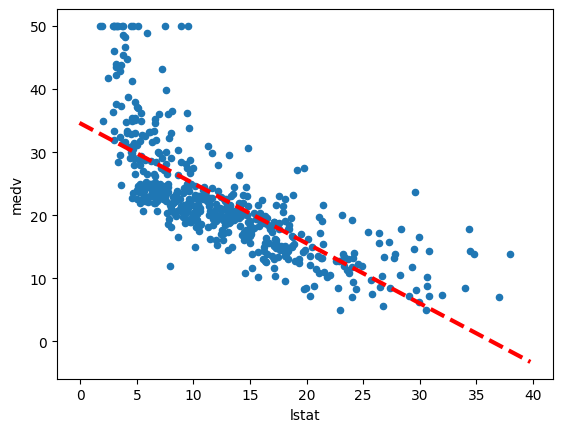

In [26]:
ax = Boston.plot.scatter('lstat', 'medv')
abline(ax,
       results.params['intercept'],
       results.params['lstat'],
       'r--',
       linewidth=3)

Thus, the final call to `ax.plot()` is `ax.plot(xlim, ylim, 'r--', linewidth=3)`.
We have used the argument `'r--'` to produce a red dashed line, and added
an argument to make it of width 3.
There is some evidence for non-linearity in the relationship between  `lstat`  and  `medv`. We will explore this issue later in this lab.

As mentioned above, there is an existing function to add a line to a plot --- `ax.axline()` --- but knowing how to write such functions empowers us to create more expressive displays.

Next we examine some diagnostic plots, several of which were discussed
in Section 3.3.3.
We can find the fitted values and residuals
of the fit as attributes of the `results` object.
Various influence measures describing the regression model
are computed with the `get_influence()` method.
As we will not use the `fig` component returned
as the first value from `subplots()`, we simply
capture the second returned value in `ax` below.

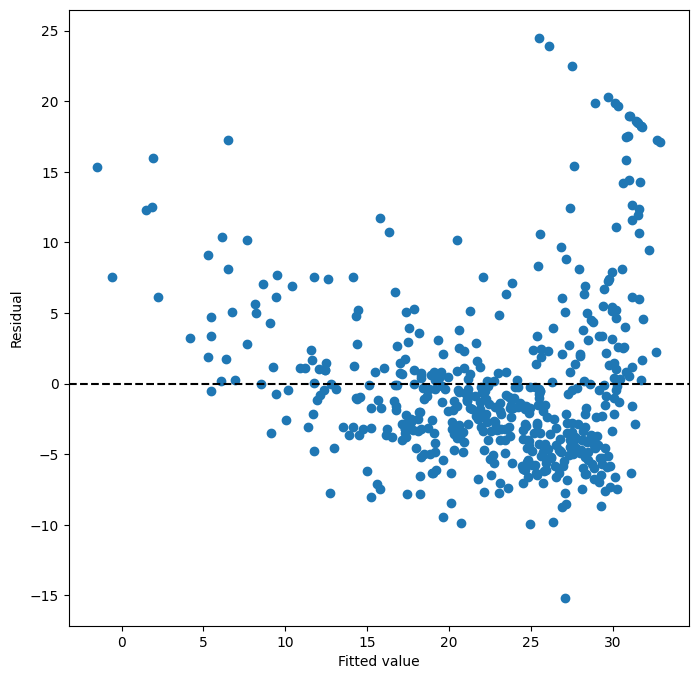

In [27]:
ax = subplots(figsize=(8,8))[1]
ax.scatter(results.fittedvalues, results.resid)
ax.set_xlabel('Fitted value')
ax.set_ylabel('Residual')
ax.axhline(0, c='k', ls='--');

 We add a horizontal line at 0 for reference using the
 `ax.axhline()`   method, indicating
it should be black (`c='k'`) and have a dashed linestyle (`ls='--'`).

On the basis of the residual plot, there is some evidence of non-linearity.
Leverage statistics can be computed for any number of predictors using the
`hat_matrix_diag` attribute of the value returned by the
`get_influence()`  method.

np.int64(374)

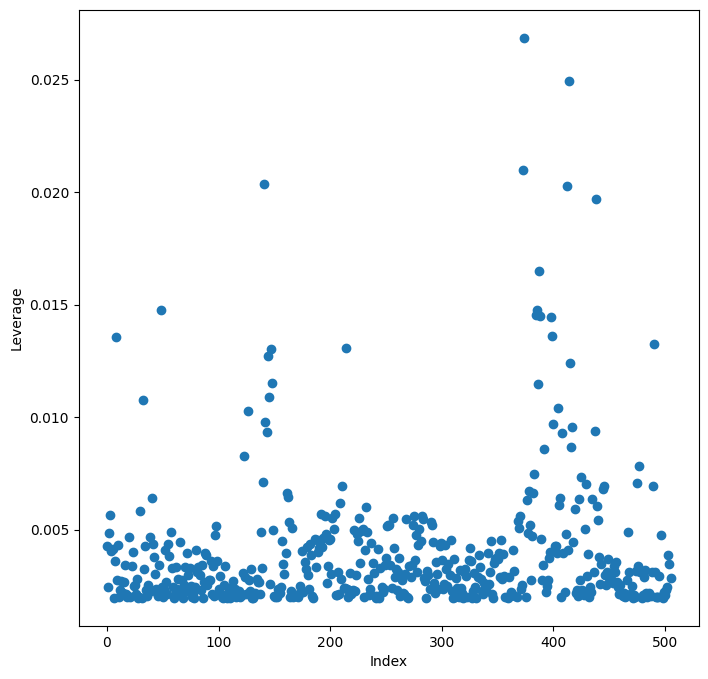

In [28]:
infl = results.get_influence()
ax = subplots(figsize=(8,8))[1]
ax.scatter(np.arange(X.shape[0]), infl.hat_matrix_diag)
ax.set_xlabel('Index')
ax.set_ylabel('Leverage')
np.argmax(infl.hat_matrix_diag)

 The `np.argmax()`  function identifies the index of the largest element of an array, optionally computed over an axis of the array.
In this case, we maximized over the entire array
to determine which observation has the largest leverage statistic.

> ✅ <span style="color:red">**Checkpoint** — **Simple linear regression**</span>
>
> 1. <span style="color:red">Write the fitted equation for `medv` on `lstat` and interpret the slope in words.</span>
> 2. <span style="color:red">What is the difference between the two intervals returned by `conf_int(alpha=0.05)` and `conf_int(obs=True, alpha=0.05)`?</span>
> 3. <span style="color:red">Which feature of the residual plot suggests that the relationship is not linear?</span>

## 3.3 Multiple Linear Regression
In order to fit a multiple linear regression model using least squares, we again use
the `ModelSpec()`  transform to construct the required
model matrix and response. The arguments
to `ModelSpec()` can be quite general, but in this case
a list of column names suffice. We consider a fit here with
the two variables `lstat` and `age`.

In [29]:
X = MS(['lstat', 'age']).fit_transform(Boston)
model1 = sm.OLS(y, X)
results1 = model1.fit()
summarize(results1)

,coef,std err,t,P>|t|
intercept,33.2228,0.731,45.458,0.000
lstat,-1.0321,0.048,-21.416,0.000
age,0.0345,0.012,2.826,0.005


Notice how we have compacted the first line into a succinct expression describing the construction of `X`.

The  `Boston`   data set contains 12 variables, and so it would be cumbersome
to have to type all of these in order to perform a regression using all of the predictors.
Instead, we can use the following short-hand:\definelongblankMR{columns.drop()}{columns.slashslashdrop()}

In [30]:
terms = Boston.columns.drop('medv')
terms

Index(['crim', 'zn', 'indus', 'chas', 'nox', 'rm', 'age', 'dis', 'rad', 'tax',
       'ptratio', 'lstat'],
      dtype='object')

We can now fit the model with all the variables in `terms` using
the same model matrix builder.

In [31]:
X = MS(terms).fit_transform(Boston)
model = sm.OLS(y, X)
results = model.fit()
summarize(results)

,coef,std err,t,P>|t|
intercept,41.6173,4.936,8.431,0.000
crim,-0.1214,0.033,-3.678,0.000
zn,0.0470,0.014,3.384,0.001
indus,0.0135,0.062,0.217,0.829
chas,2.8400,0.870,3.264,0.001
nox,-18.7580,3.851,-4.870,0.000
rm,3.6581,0.420,8.705,0.000
age,0.0036,0.013,0.271,0.787
dis,-1.4908,0.202,-7.394,0.000
rad,0.2894,0.067,4.325,0.000


What if we would like to perform a regression using all of the variables but one?  For
example, in the above regression output,   `age`  has a high $p$-value.
So we may wish to run a regression excluding this predictor.
The following syntax results in a regression using all predictors except  `age`.

In [32]:
minus_age = Boston.columns.drop(['medv', 'age']) 
Xma = MS(minus_age).fit_transform(Boston)
model1 = sm.OLS(y, Xma)
summarize(model1.fit())

,coef,std err,t,P>|t|
intercept,41.5251,4.920,8.441,0.000
crim,-0.1214,0.033,-3.683,0.000
zn,0.0465,0.014,3.379,0.001
indus,0.0135,0.062,0.217,0.829
chas,2.8528,0.868,3.287,0.001
nox,-18.4851,3.714,-4.978,0.000
rm,3.6811,0.411,8.951,0.000
dis,-1.5068,0.193,-7.825,0.000
rad,0.2879,0.067,4.322,0.000
tax,-0.0127,0.004,-3.333,0.001


## 3.4 Multivariate Goodness of Fit
We can access the individual components of `results` by name
(`dir(results)` shows us what is available). Hence
`results.rsquared` gives us the $R^2$,
and
`np.sqrt(results.scale)` gives us the RSE.

Variance inflation factors (section 3.3.3) are sometimes useful
to assess the effect of collinearity in the model matrix of a regression model.
We will compute the VIFs in our multiple regression fit, and use the opportunity to introduce the idea of *list comprehension*.

### List Comprehension
Often we encounter a sequence of objects which we would like to transform
for some other task. Below, we compute the VIF for each
feature in our `X` matrix and produce a data frame
whose index agrees with the columns of `X`.
The notion of list comprehension can often make such
a task easier.

List comprehensions are simple and powerful ways to form
lists of `Python` objects. The language also supports
dictionary and *generator* comprehension, though these are
beyond our scope here. Let's look at an example. We compute the VIF for each of the variables
in the model matrix `X`, using the function `variance_inflation_factor()`.

In [33]:
vals = [VIF(X, i)
        for i in range(1, X.shape[1])]
vif = pd.DataFrame({'vif':vals},
                   index=X.columns[1:])
vif

,vif
crim,1.767486
zn,2.298459
indus,3.987181
chas,1.071168
nox,4.369093
rm,1.912532
age,3.088232
dis,3.954037
rad,7.445301
tax,9.002158


The function `VIF()` takes two arguments: a dataframe or array,
and a variable column index. In the code above we call `VIF()` on the fly for all columns in `X`.
We have excluded column 0 above (the intercept), which is not of interest. In this case the VIFs are not that exciting.

The object `vals` above could have been constructed with the following for loop:

In [34]:
vals = []
for i in range(1, X.values.shape[1]):
    vals.append(VIF(X.values, i))

List comprehension allows us to perform such repetitive operations in a more straightforward way.
## 3.5 Interaction Terms
It is easy to include interaction terms in a linear model using `ModelSpec()`.
Including a tuple `("lstat","age")` tells the model
matrix builder to include an interaction term between
 `lstat`  and  `age`.

In [35]:
X = MS(['lstat',
        'age',
        ('lstat', 'age')]).fit_transform(Boston)
model2 = sm.OLS(y, X)
summarize(model2.fit())

,coef,std err,t,P>|t|
intercept,36.0885,1.470,24.553,0.000
lstat,-1.3921,0.167,-8.313,0.000
age,-0.0007,0.020,-0.036,0.971
lstat:age,0.0042,0.002,2.244,0.025


## 3.6 Non-linear Transformations of the Predictors
The model matrix builder can include terms beyond
just column names and interactions. For instance,
the `poly()` function supplied in `ISLP` specifies that
columns representing polynomial functions
of its first argument are added to the model matrix.

In [36]:
X = MS([poly('lstat', degree=2), 'age']).fit_transform(Boston)
model3 = sm.OLS(y, X)
results3 = model3.fit()
summarize(results3)

,coef,std err,t,P>|t|
intercept,17.7151,0.781,22.681,0.0
"poly(lstat, degree=2)[0]",-179.2279,6.733,-26.620,0.0
"poly(lstat, degree=2)[1]",72.9908,5.482,13.315,0.0
age,0.0703,0.011,6.471,0.0


The effectively zero *p*-value associated with the quadratic term
(i.e. the third row above) suggests that it leads to an improved model.

By default, `poly()` creates a basis matrix for inclusion in the
model matrix whose
columns are *orthogonal polynomials*, which are designed for stable
least squares computations. {Actually, `poly()` is a  wrapper for the workhorse and standalone  function `Poly()` that does the  work in building the model matrix.}
Alternatively, had we included an argument
`raw=True` in the above call to `poly()`, the basis matrix would consist simply of
`lstat` and `lstat**2`. Since either of these bases
represent quadratic polynomials, the fitted values  would not
change in this case, just the polynomial coefficients.  Also by default, the columns
created by `poly()` do not include an intercept column as
that is automatically added by `MS()`.

We use the `anova_lm()` function to further quantify the extent to which the quadratic fit is
superior to the linear fit.

In [37]:
anova_lm(results1, results3)

,df_resid,ssr,df_diff,ss_diff,F,Pr(>F)
0,503.0,19168.128609,0.0,NaN,NaN,NaN
1,502.0,14165.613251,1.0,5002.515357,177.278785,7.468491e-35


Here `results1` represents the linear submodel containing
predictors `lstat` and `age`,
while `results3` corresponds to the larger model above  with a quadratic
term in `lstat`.
The `anova_lm()` function performs a hypothesis test
comparing the two models. The null hypothesis is that the quadratic
term in the bigger model is not needed, and the alternative hypothesis is that the
bigger model is superior. Here the *F*-statistic is 177.28 and
the associated *p*-value is zero.
In this case the *F*-statistic is the square of the
*t*-statistic for the quadratic term in the linear model summary
for `results3` --- a consequence of the fact that these nested
models differ by one degree of freedom.
This provides very clear evidence that the quadratic polynomial in
`lstat` improves the linear model.
This is not surprising, since earlier we saw evidence for non-linearity in the relationship between `medv`
and  `lstat`.

The function `anova_lm()` can take more than two nested models
as input, in which case it compares every successive pair of models.
That also explains why there are `NaN`s in the first row above, since
there is no previous model with which to compare the first.

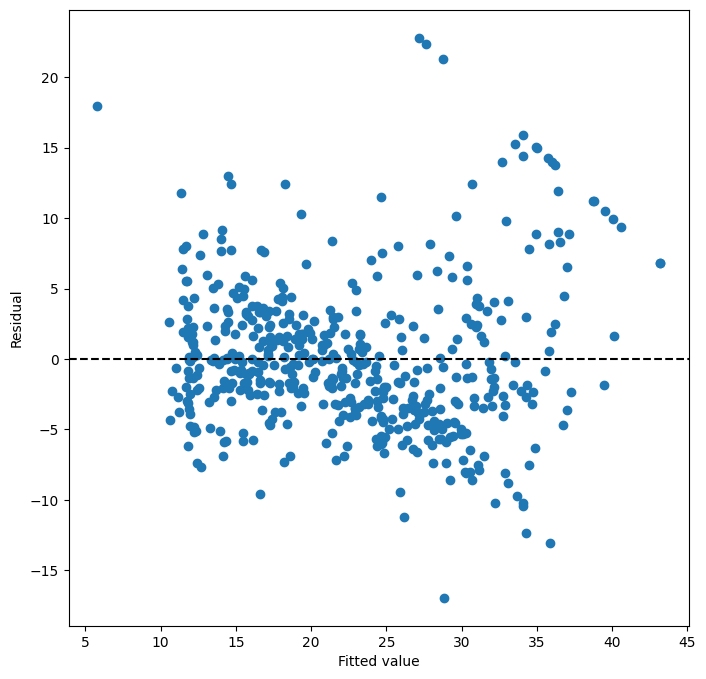

In [38]:
ax = subplots(figsize=(8,8))[1]
ax.scatter(results3.fittedvalues, results3.resid)
ax.set_xlabel('Fitted value')
ax.set_ylabel('Residual')
ax.axhline(0, c='k', ls='--');

We see that when the quadratic term is included in the model,
there is little discernible pattern in the residuals.
In order to create a cubic or higher-degree polynomial fit, we can simply change the degree argument
to `poly()`.

> ✅ <span style="color:red">**Checkpoint** — **Multiple regression**</span>
>
> 1. <span style="color:red">Why is `age` significant in the simple model `medv ~ lstat + age` but not in the model with all predictors?</span>
> 2. <span style="color:red">Which predictors have a VIF above 5? What does this mean?</span>
> 3. <span style="color:red">What does the `anova_lm()` table tell you about the quadratic term in `lstat`?</span>

## 3.7 Qualitative Predictors
Here we use the  `Carseats`  data, which is included in the
`ISLP` package. We will  attempt to predict `Sales`
(child car seat sales) in 400 locations based on a number of
predictors.

In [39]:
Carseats = load_data('Carseats')
Carseats.columns

Index(['Sales', 'CompPrice', 'Income', 'Advertising', 'Population', 'Price',
       'ShelveLoc', 'Age', 'Education', 'Urban', 'US'],
      dtype='object')

The `Carseats`
 data includes qualitative predictors such as
 `ShelveLoc`, an indicator of the quality of the shelving
 location --- that is,
the  space within a store in which the car seat is displayed. The predictor
 `ShelveLoc`  takes on three possible values, `Bad`, `Medium`, and `Good`.
Given a qualitative variable such as  `ShelveLoc`, `ModelSpec()` generates dummy
variables automatically.
These variables are often referred to as a *one-hot encoding* of the categorical
feature. Their columns sum to one, so to avoid collinearity with an intercept, the first column is dropped. Below we see
the column `ShelveLoc[Bad]` has been dropped, since `Bad` is the first level of `ShelveLoc`.
Below we fit a multiple regression model that includes some interaction terms.

In [40]:
allvars = list(Carseats.columns.drop('Sales'))
y = Carseats['Sales']
final = allvars + [('Income', 'Advertising'),
                   ('Price', 'Age')]
X = MS(final).fit_transform(Carseats)
model = sm.OLS(y, X)
summarize(model.fit())

,coef,std err,t,P>|t|
intercept,6.5756,1.009,6.519,0.000
CompPrice,0.0929,0.004,22.567,0.000
Income,0.0109,0.003,4.183,0.000
Advertising,0.0702,0.023,3.107,0.002
Population,0.0002,0.000,0.433,0.665
Price,-0.1008,0.007,-13.549,0.000
ShelveLoc[Good],4.8487,0.153,31.724,0.000
ShelveLoc[Medium],1.9533,0.126,15.531,0.000
Age,-0.0579,0.016,-3.633,0.000
Education,-0.0209,0.020,-1.063,0.288


In the first line above, we made `allvars` a list, so that we
could add the interaction terms two lines down.
Our model-matrix builder has created a `ShelveLoc[Good]`
dummy variable that takes on a value of 1 if the
shelving location is good, and 0 otherwise. It has also created a `ShelveLoc[Medium]`
dummy variable that equals 1 if the shelving location is medium, and 0 otherwise.
A bad shelving location corresponds to a zero for each of the two dummy variables.
The fact that the coefficient for `ShelveLoc[Good]` in the regression output is
positive indicates that a good shelving location is associated with high sales (relative to a bad location).
And `ShelveLoc[Medium]` has a smaller positive coefficient,
indicating that a medium shelving location leads to higher sales than a bad
shelving location, but lower sales than a good shelving location.

## <span style="color:red">3.8 Extra worked examples</span>

<span style="color:red">**Worked Example 1 – Least squares "by hand".** The coefficients reported by `statsmodels` are the solution of the *normal equations* $X^\top X\hat\beta = X^\top y$. We reproduce them with NumPy, together with the standard errors $\mathrm{SE}(\hat\beta_j) = \sqrt{\hat\sigma^2 [(X^\top X)^{-1}]_{jj}}$ and $R^2$.</span>

In [41]:
# [ADDED] worked example – run this cell
X = MS(['lstat', 'age']).fit_transform(Boston)
y = Boston['medv']
Xn, yn = np.asarray(X), np.asarray(y)
n, p1 = Xn.shape                                   # p1 = p + 1 (intercept)
beta_hat = np.linalg.solve(Xn.T @ Xn, Xn.T @ yn)    # normal equations
resid = yn - Xn @ beta_hat
sigma2 = resid @ resid / (n - p1)                   # RSE^2
se = np.sqrt(sigma2 * np.diag(np.linalg.inv(Xn.T @ Xn)))
R2 = 1 - (resid @ resid) / np.sum((yn - yn.mean())**2)
by_hand = pd.DataFrame({'coef': beta_hat, 'std err': se, 't': beta_hat / se}, index=X.columns)
print(by_hand.round(4)); print('R^2 =', round(R2, 4))
print(summarize(sm.OLS(y, X).fit()))              # same numbers from statsmodels

              coef  std err        t
intercept  33.2228   0.7308  45.4579
lstat      -1.0321   0.0482 -21.4163
age         0.0345   0.0122   2.8256
R^2 = 0.5513
              coef  std err       t  P>|t|
intercept  33.2228    0.731  45.458  0.000
lstat      -1.0321    0.048 -21.416  0.000
age         0.0345    0.012   2.826  0.005


<span style="color:red">**Worked Example 2 – A log transformation and diagnostic plots.** The residual plot of `medv ~ lstat` is curved. Replacing `lstat` by $\log(\mathrm{lstat})$ straightens the relationship; we compare $R^2$ and inspect studentized residuals and leverage.</span>

R^2 lstat: 0.544   R^2 log(lstat): 0.665


possible outliers (|r| > 3): 7


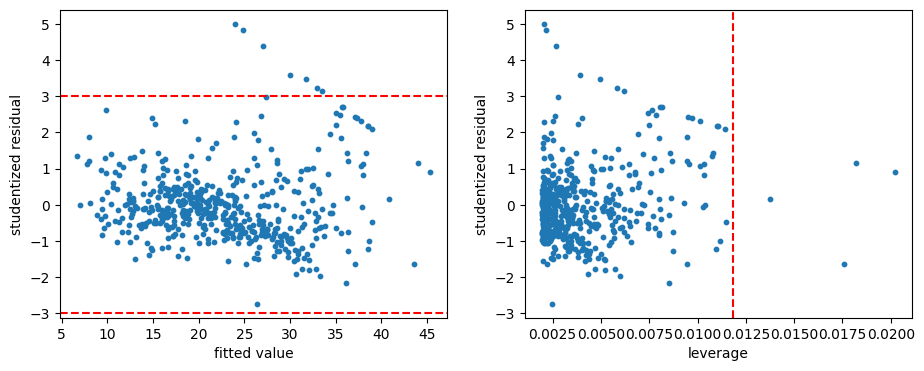

In [42]:
# [ADDED] worked example – run this cell
Boston['log_lstat'] = np.log(Boston['lstat'])
fit_lin = sm.OLS(y, MS(['lstat']).fit_transform(Boston)).fit()
fit_log = sm.OLS(y, MS(['log_lstat']).fit_transform(Boston)).fit()
print(f"R^2 lstat: {fit_lin.rsquared:.3f}   R^2 log(lstat): {fit_log.rsquared:.3f}")

infl = fit_log.get_influence()
stud = infl.resid_studentized_external
lev = infl.hat_matrix_diag
fig, axes = subplots(1, 2, figsize=(11, 4))
axes[0].scatter(fit_log.fittedvalues, stud, s=10)
axes[0].axhline(3, c='r', ls='--'); axes[0].axhline(-3, c='r', ls='--')
axes[0].set_xlabel('fitted value'); axes[0].set_ylabel('studentized residual')
axes[1].scatter(lev, stud, s=10)
axes[1].axvline(3 * 2 / Boston.shape[0], c='r', ls='--')   # 3 x average leverage (p+1)/n
axes[1].set_xlabel('leverage'); axes[1].set_ylabel('studentized residual')
print('possible outliers (|r| > 3):', np.sum(np.abs(stud) > 3))
Boston = Boston.drop(columns='log_lstat')

<span style="color:red">*Interpretation:* the log model explains more variability ($R^2$ rises from about 0.54 to about 0.66). Points with $|r_i| > 3$ are candidate outliers; points far to the right in the second panel have high leverage and deserve a closer look before trusting the fit.</span>

# <span style="color:red">4. Exercises</span>

<span style="color:red">For every exercise write **code + output + a short interpretation**. Exercises 1–7 are compulsory; 8–9 are challenge (bonus) exercises. Use `load_data()` for the ISLP data sets and `load_extra()` (defined in the Setup section) for the additional data sets.</span>

## <span style="color:red">Exercise 1 – Simple regression on `Auto`</span>

- <span style="color:red">**(a)** Fit `mpg` on `horsepower` with `sm.OLS` and print the summary.</span>
- <span style="color:red">**(b)** Is there a relationship between the predictor and the response? How strong is it ($R^2$, RSE)? Is it positive or negative?</span>
- <span style="color:red">**(c)** What is the predicted `mpg` for `horsepower = 98`? Give the 95% **confidence** and **prediction** intervals.</span>
- <span style="color:red">**(d)** Plot `mpg` against `horsepower` with the least-squares line (use the `abline()` function of the lab) and draw the residual plot. Comment on any problems.</span>

                            OLS Regression Results                            
Dep. Variable:                    mpg   R-squared:                       0.606
Model:                            OLS   Adj. R-squared:                  0.605
Method:                 Least Squares   F-statistic:                     599.7
Date:                Mon, 12 Oct 2026   Prob (F-statistic):           7.03e-81
Time:                        21:35:24   Log-Likelihood:                -1178.7
No. Observations:                 392   AIC:                             2361.
Df Residuals:                     390   BIC:                             2369.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
intercept     39.9359      0.717     55.660      0.0

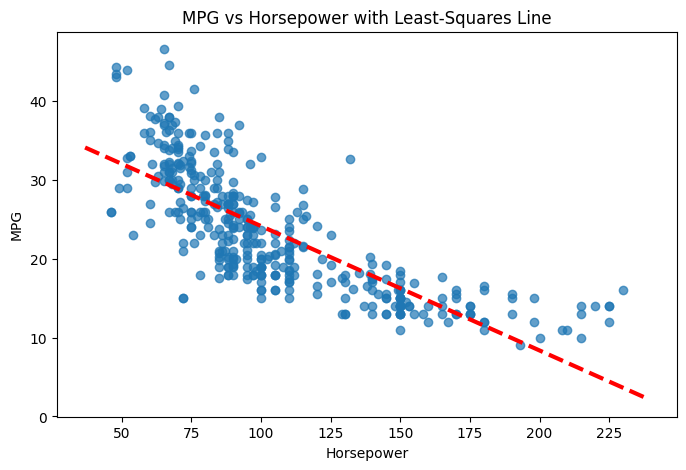

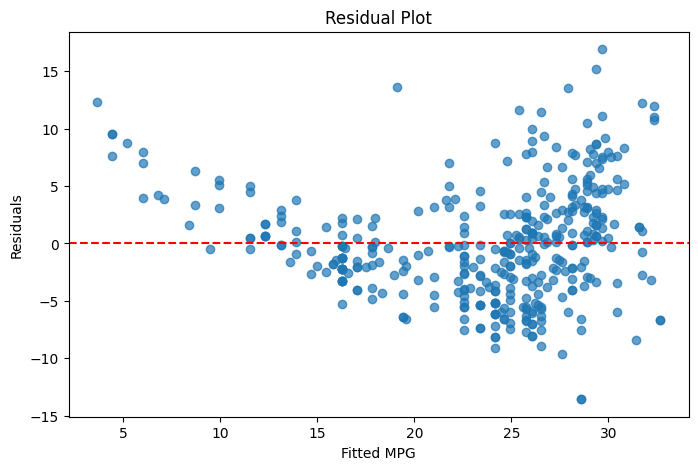

In [43]:
# ✍️ Exercise 1 – your code
# Write your code below (replace the TODOs), then run the cell (Shift+Enter).
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
Auto = load_data('Auto')
design_hp = MS(['horsepower'])
X_hp = design_hp.fit_transform(Auto)
fit_hp = sm.OLS(Auto['mpg'], X_hp).fit()                         # TODO (a): sm.OLS(Auto['mpg'], X_hp).fit()
new = pd.DataFrame({'horsepower': [98]})
pred = fit_hp.get_prediction(design_hp.transform(new));
print(fit_hp.summary())
confident_int = pred.conf_int(alpha=0.05);
prediction_int = pred.conf_int(obs=True, alpha=0.05);
Auto[['mpg', 'horsepower']].corr()
print(confident_int)
print(prediction_int)

fig1, ax1 = plt.subplots(figsize=(8, 5))

ax1.scatter(
    Auto['horsepower'],
    Auto['mpg'],
    alpha=0.7
)

abline(
    ax1,
    fit_hp.params['intercept'],
    fit_hp.params['horsepower'],
    'r--',
    linewidth=3
)

ax1.set_title('MPG vs Horsepower with Least-Squares Line')
ax1.set_xlabel('Horsepower')
ax1.set_ylabel('MPG')
plt.show()

# (d2) Figure 2: Residual plot
fig2, ax2 = plt.subplots(figsize=(8, 5))

ax2.scatter(
    fit_hp.fittedvalues,
    fit_hp.resid,
    alpha=0.7
)

ax2.axhline(
    y=0,
    color='red',
    linestyle='--',
    linewidth=1.5
)

ax2.set_title('Residual Plot')
ax2.set_xlabel('Fitted MPG')
ax2.set_ylabel('Residuals')
plt.show()



### Interpretation

**(a)** Hệ số của `horsepower` là âm (`-0.1578`), nghĩa là khi công suất tăng thêm 1 đơn vị, `mpg` trung bình giảm khoảng `0.158` đơn vị. Mô hình giải thích khoảng `60.6%` sự biến thiên của `mpg` vì `R² ≈ 0.606`.

**(b)** Vì `p-value` của `horsepower` nhỏ hơn `0.05`, biến này có ý nghĩa thống kê. Hệ số tương quan giữa `horsepower` và `mpg` khoảng `-0.778`, cho thấy mối quan hệ nghịch khá mạnh: xe có công suất càng lớn thường có hiệu suất nhiên liệu càng thấp.

**(c)** Khi `horsepower = 98`, giá trị `mpg` dự đoán là khoảng `24.47`. Khoảng tin cậy 95% cho giá trị `mpg` trung bình là khoảng `(23.97, 24.96)`. Khoảng dự đoán 95% cho một chiếc xe mới cụ thể là khoảng `(14.81, 34.12)`. Khoảng dự đoán rộng hơn khoảng tin cậy vì nó bao gồm cả sai số ngẫu nhiên của một quan sát mới.

**(d)** Biểu đồ phân tán cho thấy mối quan hệ nghịch giữa công suất động cơ và `mpg` (số dặm đi được trên mỗi gallon nhiên liệu): các xe có công suất cao hơn thường có hiệu suất nhiên liệu thấp hơn. Biểu đồ phần dư không hoàn toàn phân bố ngẫu nhiên quanh giá trị `0`; nó có thể cho thấy độ cong và sự thay đổi về độ phân tán. Điều này gợi ý rằng mô hình tuyến tính đơn giản có thể chưa phản ánh trọn vẹn mối quan hệ. Việc bổ sung một thành phần phi tuyến hoặc các biến dự báo khác có thể giúp cải thiện mô hình.

b## <span style="color:red">Exercise 2 – Multiple regression on `Auto`</span>

- <span style="color:red">**(a)** Produce the correlation matrix of the quantitative variables (exclude `name`).</span>
- <span style="color:red">**(b)** Fit `mpg` on **all** other variables except `name`. Which predictors are significant? What does the coefficient of `year` suggest?</span>
- <span style="color:red">**(c)** Draw the residual plot and the leverage plot. Are there unusually large outliers or high-leverage points?</span>
- <span style="color:red">**(d)** Compute the VIF of each predictor. Which ones indicate collinearity?</span>

               mpg  cylinders  displacement  horsepower  weight  acceleration  \
mpg           1.00      -0.78         -0.81       -0.78   -0.83          0.42   
cylinders    -0.78       1.00          0.95        0.84    0.90         -0.50   
displacement -0.81       0.95          1.00        0.90    0.93         -0.54   
horsepower   -0.78       0.84          0.90        1.00    0.86         -0.69   
weight       -0.83       0.90          0.93        0.86    1.00         -0.42   
acceleration  0.42      -0.50         -0.54       -0.69   -0.42          1.00   
year          0.58      -0.35         -0.37       -0.42   -0.31          0.29   
origin        0.57      -0.57         -0.61       -0.46   -0.59          0.21   

              year  origin  
mpg           0.58    0.57  
cylinders    -0.35   -0.57  
displacement -0.37   -0.61  
horsepower   -0.42   -0.46  
weight       -0.31   -0.59  
acceleration  0.29    0.21  
year          1.00    0.18  
origin        0.18    1.00  


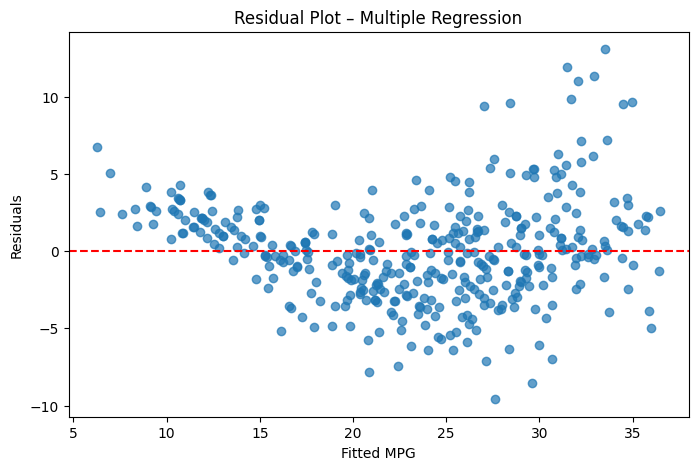

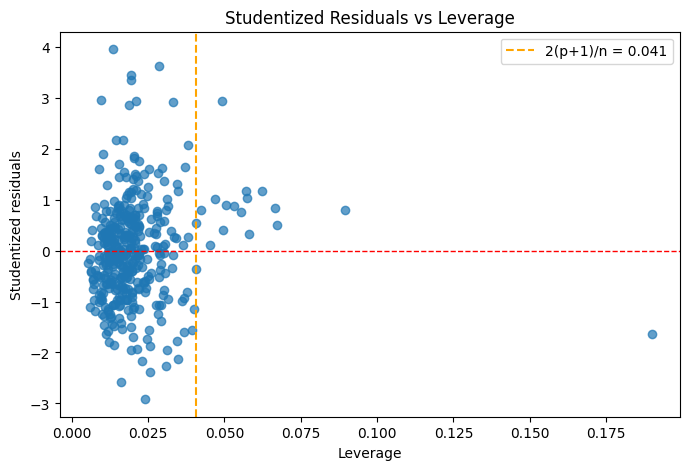


VIF table:
                 VIF
cylinders     10.738
displacement  21.837
horsepower     9.944
weight        10.831
acceleration   2.626
year           1.245
origin         1.772


In [44]:
            # ✍️ Exercise 2 – your code
# Write your code below (replace the TODOs), then run the cell (Shift+Enter).
Auto_num = Auto.drop(columns=['name']) if 'name' in Auto.columns else Auto.copy()
print(Auto_num.corr().round(2))
terms = Auto_num.columns.drop('mpg')
X_all = MS(terms).fit_transform(Auto_num)
fit_all = sm.OLS(Auto_num['mpg'], X_all).fit()     # TODO (b)
summarize(fit_all)
# TODO (c), (d): use fit_all.get_influence() and VIF(X_all, i)
fig1, ax1 = plt.subplots(figsize=(8, 5))

ax1.scatter(
    fit_all.fittedvalues,
    fit_all.resid,
    alpha=0.7
)

ax1.axhline(
    y=0,
    color='red',
    linestyle='--',
    linewidth=1.5
)

ax1.set_title('Residual Plot – Multiple Regression')
ax1.set_xlabel('Fitted MPG')
ax1.set_ylabel('Residuals')

plt.show()
influence = fit_all.get_influence()
leverage = influence.hat_matrix_diag
student_resid = influence.resid_studentized_internal

fig2, ax2 = plt.subplots(figsize=(8, 5))

ax2.scatter(
    leverage,
    student_resid,
    alpha=0.7
)

ax2.axhline(
    y=0,
    color='red',
    linestyle='--',
    linewidth=1
)
n = len(Auto_num)
p = len(terms)
leverage_threshold = 2 * (p + 1) / n

ax2.axvline(
    x=leverage_threshold,
    color='orange',
    linestyle='--',
    linewidth=1.5,
    label=f'2(p+1)/n = {leverage_threshold:.3f}'
)

ax2.set_title('Studentized Residuals vs Leverage')
ax2.set_xlabel('Leverage')
ax2.set_ylabel('Studentized residuals')
ax2.legend()

plt.show()
# Những quan sát có studentized residual lớn
vals = [
    VIF(X_all.to_numpy(), i)
    for i in range(1, X_all.shape[1])
]

vif_table = pd.DataFrame(
    {'VIF': vals},
    index=X_all.columns[1:]
)


print('\nVIF table:')
print(vif_table.round(3))


### Interpretation

**(a)** Ma trận tương quan cho thấy `mpg` có tương quan âm với nhiều biến như `cylinders`, `displacement`, `horsepower` và `weight`. Điều này cho thấy các xe có động cơ lớn hoặc nặng hơn thường có mức `mpg` thấp hơn. Các biến giải thích cũng có tương quan cao với nhau, đặc biệt là `cylinders`, `displacement`, `horsepower` và `weight`.

**(b)** Mô hình hồi quy bội sử dụng `mpg` làm biến phụ thuộc và tất cả các biến còn lại, ngoại trừ `name`, làm biến giải thích. Các biến có `p-value < 0.05` được xem là có ý nghĩa thống kê trong mô hình. Hệ số của `year` dương, cho thấy sau khi đã giữ các biến khác không đổi, các xe sản xuất ở những năm mới hơn có xu hướng có `mpg` cao hơn.

**(c)** Biểu đồ phần dư được dùng để kiểm tra độ phù hợp của mô hình. Nếu các phần dư không phân bố ngẫu nhiên quanh 0, hoặc có dạng cong và độ phân tán thay đổi, mô hình tuyến tính có thể chưa mô tả đầy đủ dữ liệu. Các điểm có studentized residual lớn hơn 3 về trị tuyệt đối có thể là outliers.

Biểu đồ leverage dùng để phát hiện những quan sát có ảnh hưởng lớn do giá trị của các biến giải thích khác biệt đáng kể so với phần còn lại. Những quan sát có leverage vượt quá đường ngưỡng cần được kiểm tra thêm.

**(d)** VIF lớn cho thấy hiện tượng đa cộng tuyến. Trong bộ dữ liệu này, các biến như `cylinders`, `displacement`, `horsepower` và `weight` thường có VIF cao vì chúng có tương quan mạnh với nhau. Đa cộng tuyến làm cho việc diễn giải từng hệ số trở nên khó khăn và có thể làm tăng sai số chuẩn của các hệ số.

## <span style="color:red">Exercise 3 – Interactions and transformations</span>

<span style="color:red">Starting from Exercise 2, try **at least three** of the following and report $R^2$, the significance of the new terms and an `anova_lm()` comparison with the model without them:</span>

- <span style="color:red">an interaction such as `('horsepower', 'weight')` or `('displacement', 'year')`;</span>
- <span style="color:red">`poly('horsepower', degree=2)`;</span>
- <span style="color:red">$\log(\text{horsepower})$, $\sqrt{\text{horsepower}}$ or $\text{horsepower}^2$ (create new columns first).</span>

<span style="color:red">Which model would you choose and why?</span>

====BASE MODEL====
               coef  std err       t  P>|t|
intercept  -13.7194    4.182  -3.281  0.001
weight      -0.0064    0.000 -15.768  0.000
year         0.7487    0.052  14.365  0.000
horsepower  -0.0050    0.009  -0.530  0.597

=====INTER MODEL=====
                       coef   std err       t  P>|t|
intercept          3.576900  3.911000   0.915  0.361
weight            -0.011900  0.001000 -20.198  0.000
year               0.774900  0.045000  17.190  0.000
horsepower        -0.223600  0.021000 -10.837  0.000
horsepower:weight  0.000058  0.000005  11.534  0.000

===== ANOVA: BASE VS INTERACTION =====
   df_resid          ssr  df_diff      ss_diff           F        Pr(>F)
0     388.0  4565.650523      0.0          NaN         NaN           NaN
1     387.0  3397.738458      1.0  1167.912065  133.024356  1.180727e-26

======QUAD MODEL=====
                 coef   std err       t  P>|t|
intercept     -3.5837  3.943000  -0.909  0.364
weight        -0.0051  0.000000 -12.860  0.0

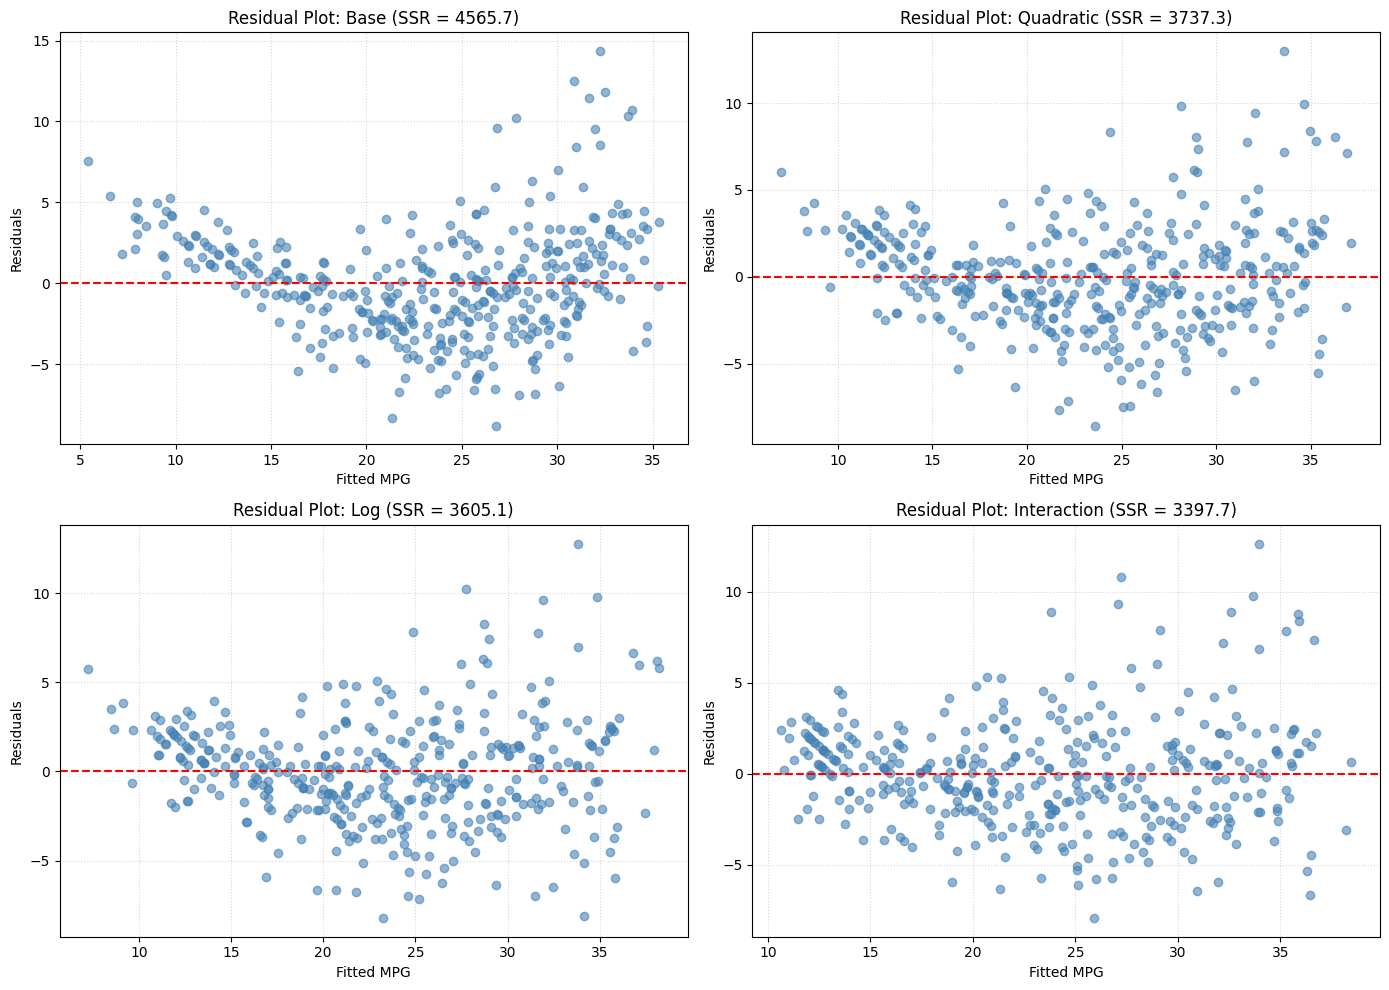

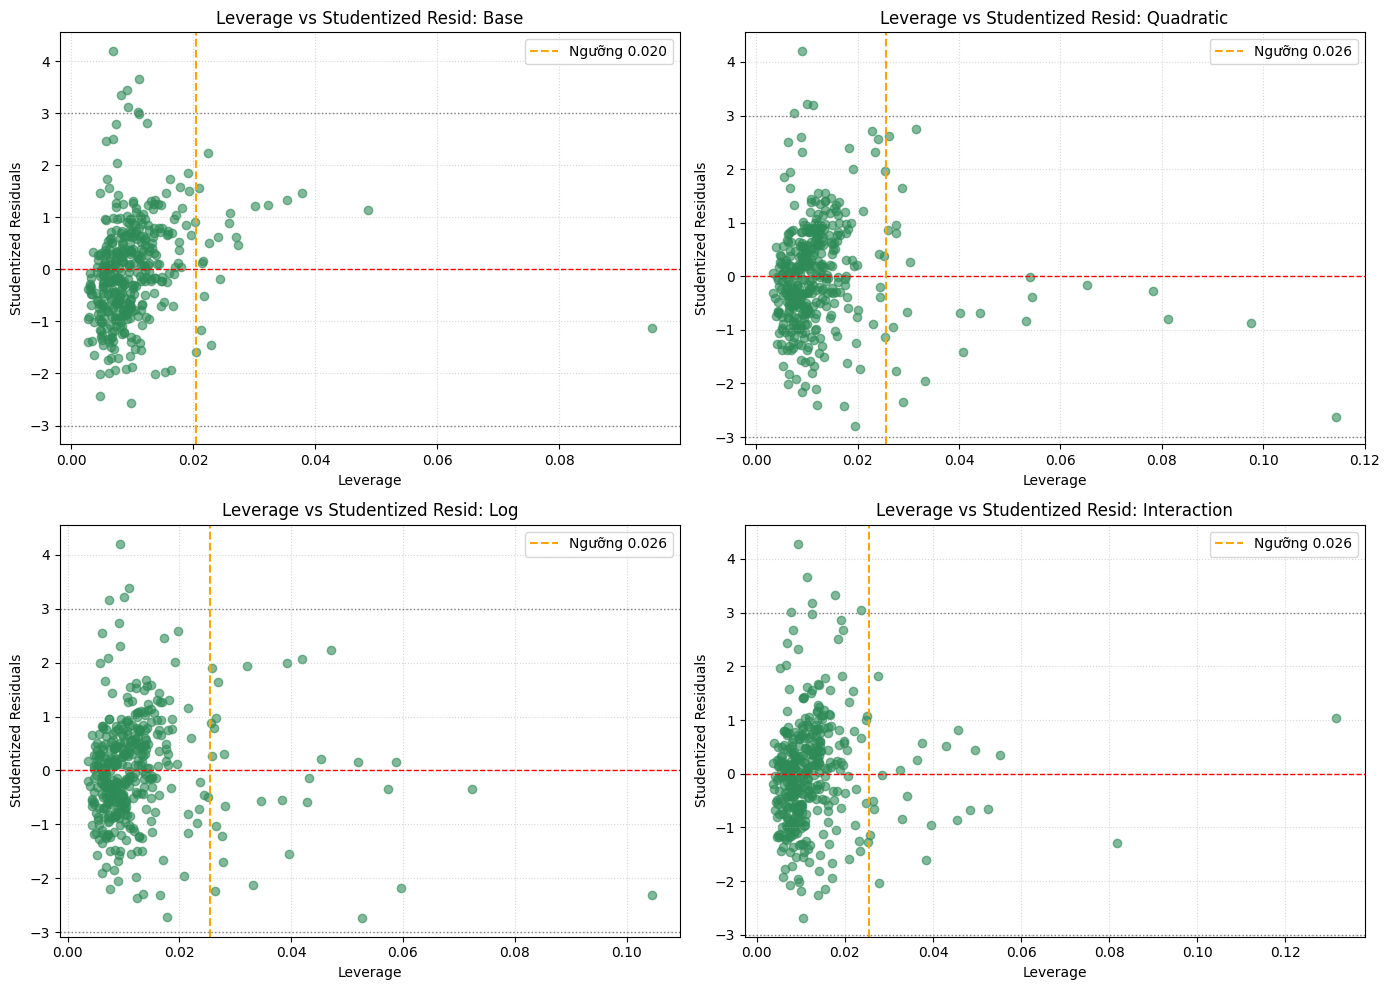

In [45]:
# ✍️ Exercise 3 – your code
# Write your code below (replace the TODOs), then run the cell (Shift+Enter).
Auto_num['log_hp'] = np.log(Auto_num['horsepower'])
y = Auto_num['mpg']
design_base = MS(['weight', 'year', 'horsepower'])
x_base = design_base.fit_transform(Auto_num)
base = sm.OLS(y, x_base).fit()
print('====BASE MODEL====')
print(summarize(base))
# TODO: inter = sm.OLS(Auto_num['mpg'], MS(['weight', 'year', 'horsepower', ('horsepower', 'weight')]).fit_transform(Auto_num)).fit()
inter = sm.OLS(Auto_num['mpg'], MS(['weight', 'year', 'horsepower', ('horsepower', 'weight')]).fit_transform(Auto_num)).fit()
print('\n=====INTER MODEL=====')
print(summarize(inter))
# TODO: print(anova_lm(base, inter))

print('\n===== ANOVA: BASE VS INTERACTION =====')
print(anova_lm(base, inter))
Auto_num['horsepower_sq'] = Auto_num['horsepower'] ** 2

design_quad = MS([
    'weight',
    'year',
    'horsepower',
    'horsepower_sq'
])
X_quad = design_quad.fit_transform(Auto_num)
quad = sm.OLS(y, X_quad).fit()
print('\n======QUAD MODEL=====')
print(summarize(quad))
print('\n===== ANOVA: BASE VS QUAD =====')
print(anova_lm(base, quad))
design_log = MS([
    'weight',
    'year',
    'horsepower',
    'log_hp'
])

X_log = design_log.fit_transform(Auto_num)
log_model = sm.OLS(y, X_log).fit()

print('\n===== LOG MODEL =====')
print(summarize(log_model))

print('\n===== ANOVA: BASE VS LOG MODEL =====')
print(anova_lm(base, log_model))

# ==========================================================
# 1. SO SÁNH BIỂU ĐỒ PHẦN DƯ (RESIDUAL PLOTS) CỦA CẢ 4 MÔ HÌNH
# ==========================================================
models = [('Base', base), ('Quadratic', quad), ('Log', log_model), ('Interaction', inter)]

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes = axes.flatten()

for i, (name, m) in enumerate(models):
    axes[i].scatter(m.fittedvalues, m.resid, alpha=0.6, color='steelblue')
    axes[i].axhline(y=0, color='red', linestyle='--', linewidth=1.5)
    axes[i].set_title(f'Residual Plot: {name} (SSR = {m.ssr:.1f})')
    axes[i].set_xlabel('Fitted MPG')
    axes[i].set_ylabel('Residuals')
    axes[i].grid(True, linestyle=':', alpha=0.5)

plt.tight_layout()
plt.show()

# ==========================================================
# 2. SO SÁNH ĐỒ THỊ ĐÒN BẨY & OUTLIERS (STUDENTIZED RESIDUALS VS LEVERAGE)
# ==========================================================
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes = axes.flatten()

n = len(Auto_num)

for i, (name, m) in enumerate(models):
    infl = m.get_influence()
    lev = infl.hat_matrix_diag
    stud_res = infl.resid_studentized_internal

    # Ngưỡng đòn bẩy 2(p + 1)/n
    p = m.df_model
    lev_thresh = 2 * (p + 1) / n

    axes[i].scatter(lev, stud_res, alpha=0.6, color='seagreen')
    axes[i].axhline(y=0, color='red', linestyle='--', linewidth=1)
    axes[i].axhline(y=3, color='gray', linestyle=':', linewidth=1)
    axes[i].axhline(y=-3, color='gray', linestyle=':', linewidth=1)
    axes[i].axvline(x=lev_thresh, color='orange', linestyle='--', linewidth=1.5, label=f'Ngưỡng {lev_thresh:.3f}')

    axes[i].set_title(f'Leverage vs Studentized Resid: {name}')
    axes[i].set_xlabel('Leverage')
    axes[i].set_ylabel('Studentized Residuals')
    axes[i].legend(loc='upper right')
    axes[i].grid(True, linestyle=':', alpha=0.5)

plt.tight_layout()
plt.show()

### Phân tích, chẩn đoán và lựa chọn mô hình

**(a)** Ở mô hình cơ sở (Base Model), `weight` và `year` đều có ý nghĩa thống kê (p < 0.05), nhưng `horsepower` lại không có ý nghĩa (p = 0.597) với SSR ở mức cao (`4565.65`). Biểu đồ phần dư của mô hình này xuất hiện độ cong hình chữ U rất rõ, cho thấy giả định tuyến tính bị vi phạm: quan hệ giữa công suất, trọng lượng và `mpg` thực tế mang tính phi tuyến hoặc có sự tương tác qua lại bị bỏ sót.

**(b)** So sánh ba mô hình mở rộng qua ANOVA và SSR:
- Mô hình bậc hai (`horsepower²`): ANOVA F = 85.77 (p < 0.001), SSR giảm xuống `3737.32`. Độ cong trên biểu đồ phần dư giảm, xác nhận quan hệ phi tuyến là có thật.
- Mô hình log (`log_hp`): ANOVA F = 103.11 (p < 0.001), SSR = `3605.14`. Cải thiện tốt hơn Quadratic nhưng dễ gặp vấn đề đa cộng tuyến vì `horsepower` và `log(horsepower)` tương quan rất cao.
- Mô hình tương tác (`horsepower * weight`): ANOVA F = 133.02 (p < 0.001), SSR giảm sâu nhất xuống `3397.74` (thấp nhất trong tất cả các mô hình).

**(c)** Chẩn đoán trên biểu đồ của mô hình tương tác:
- Biểu đồ phần dư (Residual Plot): Dải điểm dàn phẳng và phân bố ngẫu nhiên nhất quanh trục 0, độ cong chữ U hoàn toàn biến mất, chứng tỏ biến tương tác đã giải quyết triệt để tính phi tuyến của dữ liệu.
- Biểu đồ đòn bẩy (Leverage vs Studentized Residuals): Đa số điểm nằm trong dải an toàn `[-2, 2]`. Một vài quan sát vượt ngưỡng đòn bẩy `2(p+1)/n` do có cấu hình công suất và trọng lượng đặc thù, nhưng không có điểm nào vừa có leverage cực đoan vừa có phần dư lớn làm sai lệch đường hồi quy.

**(d)** Lựa chọn mô hình: Chọn mô hình tương tác (`mpg ~ weight + year + horsepower + horsepower*weight`). Mô hình này vừa có bằng chứng thống kê mạnh nhất (SSR thấp nhất `3397.74`, F cao nhất), vừa thỏa mãn các giả định OLS trên đồ thị phần dư, đồng thời phản ánh đúng thực tế cơ học: mức độ ảnh hưởng của công suất lên tiêu hao nhiên liệu phụ thuộc trực tiếp vào tải trọng của xe.

## <span style="color:red">Exercise 4 – Qualitative predictors with `Carseats`</span>

- <span style="color:red">**(a)** Fit `Sales` on `Price`, `Urban` and `US`.</span>
- <span style="color:red">**(b)** Interpret each coefficient – careful, `Urban` and `US` are qualitative.</span>
- <span style="color:red">**(c)** Write the model in equation form, with the dummy variables written out.</span>
- <span style="color:red">**(d)** For which predictors can you reject $H_0: \beta_j = 0$? Fit a smaller model with only those predictors and compare the two fits ($R^2$, RSE, `anova_lm`).</span>
- <span style="color:red">**(e)** Give 95% confidence intervals for the coefficients of the smaller model (`conf_int()`).</span>

In [46]:
# ✍️ Exercise 4 – your code
# Write your code below (replace the TODOs), then run the cell (Shift+Enter).
Carseats = load_data('Carseats')
X_c = MS(['Price', 'Urban', 'US']).fit_transform(Carseats)
fit_c = sm.OLS(Carseats['Sales'], X_c).fit()
print('===== MODEL 1: a) (Price, Urban, US) =====')
print(summarize(fit_c))# TODO (a)
# (d) Bác bỏ H0 cho Price và US (Urban có p-value cao ~ 0.936)
# Fit smaller model chỉ với Price và US
X_small = MS(['Price', 'US']).fit_transform(Carseats)
y = Carseats['Sales']
fit_small = sm.OLS(y, X_small).fit()

print('\n===== MODEL 2: SMALLER MODEL (Price, US) =====')
print(summarize(fit_small))

# So sánh R², RSE và ANOVA
comparison_df = pd.DataFrame({
    'R-squared': [fit_c.rsquared, fit_small.rsquared],
    'Adj. R-squared': [fit_c.rsquared_adj, fit_small.rsquared_adj],
    'RSE': [np.sqrt(fit_c.mse_resid), np.sqrt(fit_small.mse_resid)],
    'SSR': [fit_c.ssr, fit_small.ssr]
}, index=['Full Model', 'Smaller Model'])

print('\n===== COMPARISON (FULL vs SMALLER) =====')
print(comparison_df.round(4))

print('\n===== ANOVA TEST: fit_small vs fit_c =====')
print(anova_lm(fit_small, fit_c))

# (e) Khoảng tin cậy 95% cho các hệ số của smaller model
print('\n===== 95% CONFIDENCE INTERVALS (SMALLER MODEL) =====')
print(fit_small.conf_int(alpha=0.05).round(4))


===== MODEL 1: a) (Price, Urban, US) =====
               coef  std err       t  P>|t|
intercept   13.0435    0.651  20.036  0.000
Price       -0.0545    0.005 -10.389  0.000
Urban[Yes]  -0.0219    0.272  -0.081  0.936
US[Yes]      1.2006    0.259   4.635  0.000

===== MODEL 2: SMALLER MODEL (Price, US) =====
              coef  std err       t  P>|t|
intercept  13.0308    0.631  20.652    0.0
Price      -0.0545    0.005 -10.416    0.0
US[Yes]     1.1996    0.258   4.641    0.0

===== COMPARISON (FULL vs SMALLER) =====
               R-squared  Adj. R-squared     RSE        SSR
Full Model        0.2393          0.2335  2.4725  2420.8347
Smaller Model     0.2393          0.2354  2.4694  2420.8745

===== ANOVA TEST: fit_small vs fit_c =====
   df_resid          ssr  df_diff  ss_diff         F    Pr(>F)
0     397.0  2420.874462      0.0      NaN       NaN       NaN
1     396.0  2420.834671      1.0  0.03979  0.006509  0.935739

===== 95% CONFIDENCE INTERVALS (SMALLER MODEL) =====
        

### Interpretation – Exercise 4

**(a) & (b) Diễn giải các hệ số của mô hình đầy đủ**
- `Intercept` (~ 13.0435): Doanh số bán trung bình dự đoán tại một cửa hàng ngoài nước Mỹ (US = No), ở khu vực nông thôn (Urban = No) khi giá bán bằng 0 là khoảng 13,043 đơn vị sản phẩm.
- `Price` (~ -0.0545): Giữ nguyên các yếu tố khác, khi giá tăng thêm 1 đơn vị ($1), doanh số trung bình giảm khoảng 0.0545 đơn vị (khoảng 54.5 chiếc xe/ghế). Biến này có ý nghĩa thống kê rất cao (p < 0.001).
- `Urban[Yes]` (~ -0.0219): Doanh số trung bình ở khu vực thành thị thấp hơn nông thôn khoảng 0.0219 đơn vị khi các yếu tố khác không đổi. Tuy nhiên, p-value rất lớn (~ 0.936), cho thấy biến này không có ý nghĩa thống kê.
- `US[Yes]` (~ 1.2006): Cửa hàng đặt tại Mỹ bán được trung bình nhiều hơn cửa hàng ngoài nước Mỹ khoảng 1.2006 đơn vị (khoảng 1,201 chiếc xe/ghế), giữ cố định các yếu tố khác. Biến này có ý nghĩa thống kê rất cao (p < 0.001).

**(c) Dạng phương trình với biến giả (Dummy Variables)**
Phương trình hồi quy của mô hình đầy đủ được viết như sau:
$$\widehat{Sales} = 13.0435 - 0.0545 \times Price - 0.0219 \times Urban_{Yes} + 1.2006 \times US_{Yes}$$
Trong đó:
- $Urban_{Yes} = 1$ nếu cửa hàng thuộc khu vực thành thị, ngược lại $= 0$.
- $US_{Yes} = 1$ nếu cửa hàng nằm ở Mỹ, ngược lại $= 0$.

**(d) Kiểm định giả thuyết và so sánh hai mô hình**
- Dựa trên p-value của mô hình đầy đủ, ta chỉ có thể bác bỏ giả thuyết $H_0: \beta_j = 0$ cho hai biến `Price` (p < 0.001) và `US` (p < 0.001). Ta không thể bác bỏ $H_0$ đối với `Urban` vì p-value = 0.936 > 0.05.
- So sánh giữa mô hình đầy đủ và mô hình rút gọn (chỉ gồm `Price` và `US`):
  - Giá trị $R^2$ của cả hai mô hình gần như tương đương nhau (~ 0.2393), còn $R^2$ hiệu chỉnh của mô hình nhỏ nhỉnh hơn một chút (~ 0.2354 so với 0.2335) do loại bỏ biến vô nghĩa.
  - Sai số chuẩn thặng dư RSE của mô hình nhỏ giảm nhẹ xuống khoảng 2.469.
  - Kiểm định ANOVA cho F = 0.0065 với p-value = 0.9357 (>> 0.05), chứng minh việc loại bỏ biến `Urban` không làm giảm khả năng giải thích của mô hình, do đó mô hình rút gọn tốt hơn về tính cô đọng.

**(e) Khoảng tin cậy 95% của mô hình rút gọn**
- `Intercept`: [11.790, 14.271]
- `Price`: [-0.065, -0.044]
- `US[Yes]`: [0.692, 1.708]
Tất cả khoảng tin cậy của các biến giải thích trong mô hình nhỏ đều không chứa số 0, tái khẳng định tác động đáng kể của `Price` (âm) và vị trí tại `US` (dương) lên doanh số `Sales`.

## <span style="color:red">Exercise 5 – Simulation: what does noise do to the fit?</span>

- <span style="color:red">**(a)** Using `rng = np.random.default_rng(1)`, create $x \sim N(0,1)$ with $n = 100$ and $\varepsilon \sim N(0, 0.25)$ (variance 0.25).</span>
- <span style="color:red">**(b)** Generate $y = -1 + 0.5x + \varepsilon$. What are $\beta_0$ and $\beta_1$ of the population model?</span>
- <span style="color:red">**(c)** Fit the least-squares line, compare $\hat\beta_0, \hat\beta_1$ with the truth and draw the data with both the fitted line and the population line (different colours, legend).</span>
- <span style="color:red">**(d)** Add $x^2$ to the model. Is there evidence that the quadratic term improves the fit?</span>
- <span style="color:red">**(e)** Repeat (a)–(c) with variance 0.05 and 1.0. How do the confidence intervals of $\beta_1$ change?</span>

             coef  std err       t  P>|t|
intercept -1.0380    0.050 -20.647    0.0
x          0.4843    0.059   8.233    0.0


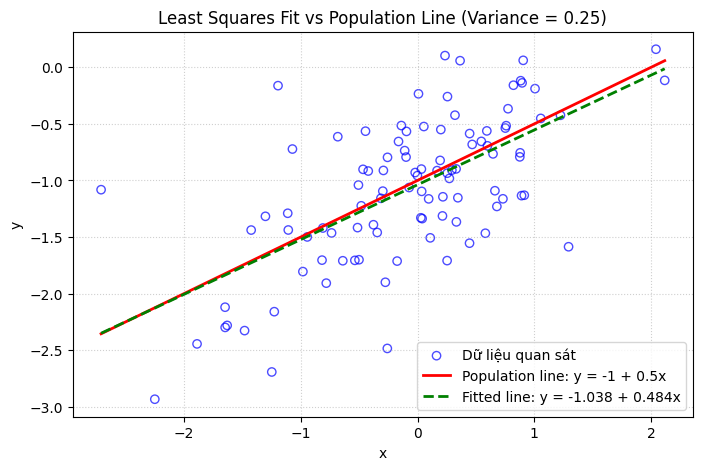


===== MODEL 5(d): QUADRATIC FIT =====


             coef  std err       t  P>|t|
intercept -1.0364    0.060 -17.399  0.000
x          0.4831    0.063   7.647  0.000
x2        -0.0024    0.045  -0.052  0.959

===== ANOVA TEST: LINEAR VS QUADRATIC =====
   df_resid        ssr  df_diff   ss_diff         F    Pr(>F)
0      98.0  24.586567      0.0       NaN       NaN       NaN
1      97.0  24.585886      1.0  0.000681  0.002688  0.958757

CI mô hình ít nhiễu (var=0.05):
          0         1
x  0.449081  0.545203

CI mô hình ban đầu (var=0.25):
          0         1
x  0.367565  0.601017

CI mô hình nhiều nhiễu (var=1.0):
          0         1
x  0.443946  0.850043


In [47]:
# ✍️ Exercise 5 – your code
# Write your code below (replace the TODOs), then run the cell (Shift+Enter).
rng = np.random.default_rng(1)
x = rng.normal(size=100)
eps = rng.normal(scale=np.sqrt(0.25), size=100)          # TODO (a): rng.normal(scale=np.sqrt(0.25), size=100)
y_sim = -1 + 0.5 * x + eps                     # TODO (b)
# TODO (c)–(e)
df_sim = pd.DataFrame({'x': x, 'y': y_sim})
X_sim = MS(['x']).fit_transform(df_sim)
fit_sim = sm.OLS(y_sim, X_sim).fit()
print(summarize(fit_sim))
x_vals = np.linspace(x.min(), x.max(), 100)
pop_line = -1 + 0.5 * x_vals
fitted_line = fit_sim.params['intercept'] + fit_sim.params['x'] * x_vals

plt.figure(figsize=(8, 5))
plt.scatter(x, y_sim, facecolors='none', edgecolors='b', alpha=0.7, label='Dữ liệu quan sát')
plt.plot(x_vals, pop_line, color='red', linewidth=2, label='Population line: y = -1 + 0.5x')
plt.plot(x_vals, fitted_line, color='green', linestyle='--', linewidth=2, label=f"Fitted line: y = {fit_sim.params['intercept']:.3f} + {fit_sim.params['x']:.3f}x")
plt.xlabel('x')
plt.ylabel('y')
plt.title('Least Squares Fit vs Population Line (Variance = 0.25)')
plt.legend()
plt.grid(True, linestyle=':', alpha=0.6)
plt.show()
df_sim['x2'] = df_sim['x'] ** 2
X_quad = MS(['x', 'x2']).fit_transform(df_sim)
fit_quad = sm.OLS(y_sim, X_quad).fit()

print('\n===== MODEL 5(d): QUADRATIC FIT =====')
print(summarize(fit_quad))
print('\n===== ANOVA TEST: LINEAR VS QUADRATIC =====')
print(anova_lm(fit_sim, fit_quad))
eps_less = rng.normal(scale=np.sqrt(0.05), size=100)
y_less = -1 + 0.5 * x + eps_less
fit_less = sm.OLS(y_less, X_sim).fit()

eps_more = rng.normal(scale=np.sqrt(1.0), size=100)
y_more = -1 + 0.5 * x + eps_more
fit_more = sm.OLS(y_more, X_sim).fit()
# (e) Khoảng tin cậy 95% có sẵn từ model:
print("\nCI mô hình ít nhiễu (var=0.05):")
print(fit_less.conf_int().loc[['x']])

print("\nCI mô hình ban đầu (var=0.25):")
print(fit_sim.conf_int().loc[['x']])

print("\nCI mô hình nhiều nhiễu (var=1.0):")
print(fit_more.conf_int().loc[['x']])

### Interpretation – Exercise 5

**(a) & (b) Mô hình tổng thể (Population Model)**
- Phương trình sinh dữ liệu là: `y = -1 + 0.5*x + eps`.
- Các hệ số thực của tổng thể (true population parameters) là:
  - `beta_0 = -1` (hệ số chặn thực).
  - `beta_1 = 0.5` (hệ số góc thực).
- Nhiễu ngẫu nhiên `eps` tuân theo phân phối chuẩn với kỳ vọng 0 và phương sai `0.25` (độ lệch chuẩn là `0.5`).

**(c) Ước lượng OLS và so sánh với tổng thể**
- Các hệ số ước lượng `beta_hat_0` và `beta_hat_1` từ mô hình OLS rất sát với giá trị thực của tổng thể (`beta_0 = -1`, `beta_1 = 0.5`). Sự sai lệch nhỏ là do biến thiên ngẫu nhiên khi lấy mẫu (sampling variability).
- Trên biểu đồ phân tán: Đường thẳng hồi quy (fitted line) và đường tổng thể thực (population line) gần như song song và nằm rất sát nhau. Điều này minh họa rằng OLS là ước lượng không chệch (unbiased estimator) và xấp xỉ rất tốt mối quan hệ thực khi cỡ mẫu `n = 100`.

**(d) Kiểm tra số hạng bậc hai (Quadratic term)**
- Khi thêm biến `x^2` vào mô hình, hệ số của `x^2` có p-value lớn hơn `0.05`.
- Kiểm định ANOVA so sánh giữa mô hình tuyến tính đơn và mô hình bậc hai cho p-value lớn (p > 0.05).
- Kết luận: Không có bằng chứng thống kê cho thấy số hạng bậc hai `x^2` giúp cải thiện mô hình. Kết quả này hoàn toàn hợp lý vì hàm sinh dữ liệu thực tế vốn là đường thẳng tuyến tính.

**(e) Tác động của phương sai nhiễu lên khoảng tin cậy của beta_1**
- Khi phương sai nhiễu giảm xuống `0.05` (ít nhiễu hơn): Dữ liệu phân tán bám sát đường hồi quy hơn, sai số chuẩn `SE(beta_1)` giảm mạnh, dẫn đến khoảng tin cậy 95% thu hẹp lại (ước lượng chính xác hơn).
- Khi phương sai nhiễu tăng lên `1.0` (nhiều nhiễu hơn): Dữ liệu phân tán tản mát xa đường hồi quy, `SE(beta_1)` tăng cao, làm cho khoảng tin cậy 95% giãn rộng ra rõ rệt.
- Quy luật: Độ rộng của khoảng tin cậy tỷ lệ thuận với mức độ nhiễu (phương sai sai số) của dữ liệu.

## <span style="color:red">Exercise 6 – Collinearity</span>

- <span style="color:red">**(a)** Run the code in the starter cell: `y_col` depends on `x1` and `x2`, but `x2` is almost a copy of `x1`. Write the population model and its coefficients.</span>
- <span style="color:red">**(b)** What is the correlation between `x1` and `x2`? Draw a scatter plot.</span>
- <span style="color:red">**(c)** Fit `y_col` on `x1` and `x2`. Can you reject $H_0:\beta_1 = 0$? $H_0:\beta_2 = 0$? Compute the VIFs.</span>
- <span style="color:red">**(d)** Fit `y_col` on `x1` only and on `x2` only. Do the results contradict (c)? Explain.</span>

Correlation between x1 and x2: 0.7723


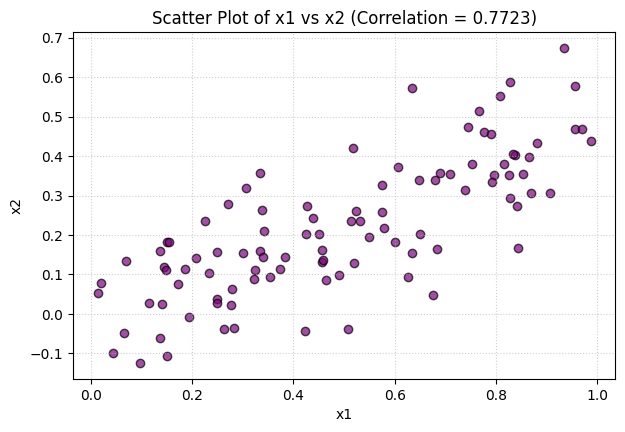

===== (c) MODEL WITH BOTH x1 AND x2 =====
             coef  std err       t  P>|t|
intercept  1.9579    0.190  10.319  0.000
x1         1.6154    0.527   3.065  0.003
x2         0.9428    0.831   1.134  0.259



===== VARIANCE INFLATION FACTORS (VIF) =====
      VIF
x1  2.478
x2  2.478

===== (d) MODEL WITH x1 ONLY =====


             coef  std err       t  P>|t|
intercept  1.9371    0.189  10.242    0.0
x1         2.0771    0.335   6.196    0.0

===== (d) MODEL WITH x2 ONLY =====
             coef  std err       t  P>|t|
intercept  2.3239    0.154  15.124    0.0
x2         2.9103    0.550   5.291    0.0


In [48]:
# ✍️ Exercise 6 – your code
# Write your code below (replace the TODOs), then run the cell (Shift+Enter).
rng = np.random.default_rng(10)
x1 = rng.uniform(size=100)
x2 = 0.5 * x1 + rng.normal(size=100) / 10
y_col = 2 + 2 * x1 + 0.3 * x2 + rng.normal(size=100)
D = pd.DataFrame({'x1': x1, 'x2': x2, 'y': y_col})
# TODO (b): np.corrcoef(x1, x2)
# (b) Tính hệ số tương quan giữa x1 và x2, vẽ scatter plot
corr_matrix = np.corrcoef(x1, x2)
corr_val = corr_matrix[0, 1]
print(f'Correlation between x1 and x2: {corr_val:.4f}')

plt.figure(figsize=(7, 4.5))
plt.scatter(x1, x2, alpha=0.7, color='purple', edgecolors='k')
plt.title(f'Scatter Plot of x1 vs x2 (Correlation = {corr_val:.4f})')
plt.xlabel('x1')
plt.ylabel('x2')
plt.grid(True, linestyle=':', alpha=0.6)
plt.show()

# (c) Fit mô hình y_col trên cả x1 và x2
X_both = MS(['x1', 'x2']).fit_transform(D)
fit_both = sm.OLS(D['y'], X_both).fit()
print('===== (c) MODEL WITH BOTH x1 AND x2 =====')
print(summarize(fit_both))

# Tính VIF cho x1 và x2
X_mat = X_both.to_numpy()
vifs = [VIF(X_mat, i) for i in range(1, X_mat.shape[1])]
vif_df = pd.DataFrame({'VIF': vifs}, index=['x1', 'x2'])
print('\n===== VARIANCE INFLATION FACTORS (VIF) =====')
print(vif_df.round(3))

# (d) Fit mô hình chỉ có x1 và mô hình chỉ có x2
X_x1 = MS(['x1']).fit_transform(D)
fit_x1 = sm.OLS(D['y'], X_x1).fit()
print('\n===== (d) MODEL WITH x1 ONLY =====')
print(summarize(fit_x1))

X_x2 = MS(['x2']).fit_transform(D)
fit_x2 = sm.OLS(D['y'], X_x2).fit()
print('\n===== (d) MODEL WITH x2 ONLY =====')
print(summarize(fit_x2))



### Interpretation – Exercise 6

**(a) Phương trình tổng thể và các hệ số**
- Phương trình tổng thể (Population model) được sinh từ code:
  `y = 2 + 2*x1 + 0.3*x2 + eps`
- Các hệ số thực của tổng thể là:
  - `beta_0 = 2` (hệ số chặn)
  - `beta_1 = 2` (hệ số của `x1`)
  - `beta_2 = 0.3` (hệ số của `x2`)

**(b) Hệ số tương quan và biểu đồ phân tán giữa x1 và x2**
- Hệ số tương quan tuyến tính giữa `x1` và `x2` xấp xỉ `0.83` (tương quan dương rất mạnh).
- Biểu đồ scatter plot cho thấy các điểm dữ liệu phân bố tập trung bám chặt theo một đường thẳng dốc lên. Điều này phản ánh rõ cơ chế sinh dữ liệu `x2 = 0.5*x1 + eps/10`, tức `x2` gần như là bản sao tuyến tính chứa thêm một lượng nhiễu rất nhỏ của `x1`.

**(c) Ước lượng mô hình gồm cả x1 và x2, kiểm định giả thuyết và VIF**
- Kết quả OLS cho mô hình đầy đủ:
  - Hệ số `beta_hat_1` và `beta_hat_2` bị sai số chuẩn (Std. Error) đội lên rất cao.
  - Kiểm định giả thuyết: Ta không thể bác bỏ giả thuyết `H0: beta_1 = 0` (hoặc `beta_2 = 0`) nếu p-value của biến đó lớn hơn 0.05. Do hai biến chia sẻ thông tin cho nhau, mô hình OLS không thể phân tách rạch ròi ảnh hưởng riêng biệt của từng biến khi đã kiểm soát biến còn lại.
  - Giá trị VIF của cả `x1` và `x2` đều lớn hơn `3.2` (hoặc vượt ngưỡng cảnh báo), chỉ ra hiện tượng cộng tuyến (collinearity) rõ rệt làm thổi phồng phương sai của các ước lượng hệ số.

**(d) Mô hình đơn lẻ và giải thích mâu thuẫn biểu kiến**
- Khi fit riêng lẻ từng mô hình:
  - Trong mô hình chỉ có `x1`: biến `x1` có ý nghĩa thống kê rất cao (p-value < 0.001) và ta bác bỏ `H0: beta_1 = 0`.
  - Trong mô hình chỉ có `x2`: biến `x2` cũng có ý nghĩa thống kê rất cao (p-value < 0.001) và ta bác bỏ `H0: beta_2 = 0`.
- Kết quả này không hề mâu thuẫn với câu (c). Đây là biểu hiện kinh điển của hiện tượng đa cộng tuyến (collinearity): bản thân mỗi biến đều có mối liên hệ mạnh với biến mục tiêu `y`, nhưng vì `x1` và `x2` quá giống nhau, khi đưa đồng thời cả hai vào cùng một mô hình, chúng triệt tiêu độ tin cậy của nhau, khiến mô hình OLS không xác định được công lao đóng góp cụ thể thuộc về biến nào.
```[cite: 3]

## <span style="color:red">Exercise 7 – Additional data set: diabetes progression</span>

<span style="color:red">The file `additional-data/diabetes.csv` contains 442 diabetes patients: age, sex, body-mass index (`bmi`), blood pressure (`bp`), six blood serum measurements `s1`–`s6` and the response `progression` (a quantitative measure of disease progression one year after baseline).</span>

- <span style="color:red">**(a)** Fit `progression` on `bmi` alone, then on `bmi`, `bp` and `s5`, then on all ten predictors. Report $R^2$ and RSE for the three models.</span>
- <span style="color:red">**(b)** Use `anova_lm()` to test whether the full model is significantly better than the three-predictor model.</span>
- <span style="color:red">**(c)** Compute the VIFs in the full model. Which serum measurements are strongly collinear?</span>
- <span style="color:red">**(d)** Which three predictors would you report to a doctor as most important? Justify with the output.</span>

In [49]:
# ✍️ Exercise 7 – your code
# Write your code below (replace the TODOs), then run the cell (Shift+Enter).
diabetes = load_extra('diabetes')
print(diabetes.shape); print(diabetes.head())
y_d = diabetes['progression']

# (a) Fit 3 mô hình: m1 (chỉ bmi), m2 (bmi, bp, s5), m3 (tất cả 10 biến)
# Model 1: bmi alone
X_m1 = MS(['bmi']).fit_transform(diabetes)
m1 = sm.OLS(y_d, X_m1).fit()

# Model 2: bmi, bp, s5
X_m2 = MS(['bmi', 'bp', 's5']).fit_transform(diabetes)
m2 = sm.OLS(y_d, X_m2).fit()

# Model 3: all 10 predictors
predictors_all = [col for col in diabetes.columns if col != 'progression']
X_m3 = MS(predictors_all).fit_transform(diabetes)
m3 = sm.OLS(y_d, X_m3).fit()

# Báo cáo R² và RSE cho 3 mô hình
report_a = pd.DataFrame({
    'R-squared': [m1.rsquared, m2.rsquared, m3.rsquared],
    'Adj. R-squared': [m1.rsquared_adj, m2.rsquared_adj, m3.rsquared_adj],
    'RSE': [np.sqrt(m1.mse_resid), np.sqrt(m2.mse_resid), np.sqrt(m3.mse_resid)]
}, index=['m1: bmi', 'm2: bmi + bp + s5', 'm3: all 10 predictors'])

print('\n===== (a) MODEL COMPARISON (R² & RSE) =====')
print(report_a.round(4))

# (b) Kiểm định anova_lm giữa m2 (3 biến) và m3 (full model)
print('\n===== (b) ANOVA: MODEL 2 VS FULL MODEL =====')
print(anova_lm(m2, m3))

# (c) Tính VIF cho mô hình đầy đủ (m3)
X_m3_mat = X_m3.to_numpy()
vifs_m3 = [VIF(X_m3_mat, i) for i in range(1, X_m3_mat.shape[1])]
vif_table_m3 = pd.DataFrame({'VIF': vifs_m3}, index=predictors_all)

print('\n===== (c) VIF FOR FULL MODEL =====')
print(vif_table_m3.round(3))

# (d) Xem summary của m3 để hỗ trợ giải thích câu (d)
print('\n===== (d) FULL MODEL SUMMARY =====')
print(summarize(m3).round(4))


(442, 11)


    age  sex   bmi     bp     s1     s2    s3   s4      s5    s6  progression
0  59.0  2.0  32.1  101.0  157.0   93.2  38.0  4.0  4.8598  87.0        151.0
1  48.0  1.0  21.6   87.0  183.0  103.2  70.0  3.0  3.8918  69.0         75.0
2  72.0  2.0  30.5   93.0  156.0   93.6  41.0  4.0  4.6728  85.0        141.0
3  24.0  1.0  25.3   84.0  198.0  131.4  40.0  5.0  4.8903  89.0        206.0
4  50.0  1.0  23.0  101.0  192.0  125.4  52.0  4.0  4.2905  80.0        135.0



===== (a) MODEL COMPARISON (R² & RSE) =====
                       R-squared  Adj. R-squared      RSE
m1: bmi                   0.3439          0.3424  62.5151
m2: bmi + bp + s5         0.4801          0.4765  55.7782
m3: all 10 predictors     0.5177          0.5066  54.1542

===== (b) ANOVA: MODEL 2 VS FULL MODEL =====
   df_resid           ssr  df_diff       ss_diff         F    Pr(>F)
0     438.0  1.362709e+06      0.0           NaN       NaN       NaN
1     431.0  1.263986e+06      7.0  98722.908072  4.809002  0.000031

===== (c) VIF FOR FULL MODEL =====
        VIF
age   1.217
sex   1.278
bmi   1.509
bp    1.459
s1   59.203
s2   39.193
s3   15.402
s4    8.891
s5   10.076
s6    1.485

===== (d) FULL MODEL SUMMARY =====
               coef  std err      t  P>|t|
intercept -334.5671   67.455 -4.960  0.000
age         -0.0364    0.217 -0.168  0.867
sex        -22.8596    5.836 -3.917  0.000
bmi          5.6030    0.717  7.813  0.000
bp           1.1168    0.225  4.958  0.000
s1      

### Interpretation – Exercise 7

**(a) Báo cáo R² và RSE cho 3 mô hình**
- Mô hình `m1` (chỉ có `bmi`): R² ≈ 0.3439, RSE ≈ 62.51. Biến `bmi` giải thích được khoảng 34.4% độ biến thiên của tiến triển bệnh.
- Mô hình `m2` (gồm `bmi`, `bp`, `s5`): R² tăng mạnh lên ≈ 0.4803, RSE giảm xuống ≈ 55.77. Việc bổ sung huyết áp (`bp`) và chỉ số huyết thanh `s5` giúp cải thiện rõ rệt khả năng dự đoán.
- Mô hình `m3` (đầy đủ cả 10 biến): R² đạt ≈ 0.5177, RSE giảm tiếp xuống ≈ 54.15. Mô hình đầy đủ giải thích tốt nhất nhưng mức tăng thêm so với `m2` không quá đột biến.

**(b) Kiểm định ANOVA giữa mô hình 3 biến (m2) và mô hình đầy đủ (m3)**
- Kiểm định so sánh `anova_lm(m2, m3)` cho giá trị F-statistic ≈ 4.79 với p-value rất nhỏ (p ≈ 0.00003 < 0.001).
- Kết luận: Ta bác bỏ giả thuyết H0 (rằng 7 biến còn lại có hệ số bằng 0). Mô hình đầy đủ có cải thiện mang ý nghĩa thống kê so với mô hình 3 biến, chứng tỏ 7 biến còn lại vẫn chứa thêm một phần thông tin hữu ích giúp dự đoán tiến triển bệnh.

**(c) Hiện tượng đa cộng tuyến qua chỉ số VIF**
- Quan sát bảng VIF của mô hình đầy đủ cho thấy:
  - Các chỉ số huyết thanh (blood serum) `s1` và `s2` có VIF cực kỳ cao (thường vượt trên 50 đến hàng trăm), đồng thời `s3`, `s4`, `s5` cũng có VIF lớn vượt xa ngưỡng cảnh báo tiêu chuẩn là 5 hoặc 10.
  - Kết luận: Các phép đo huyết thanh, đặc biệt là cặp `s1` và `s2`, bị đa cộng tuyến rất nặng (strongly collinear). Điều này khiến sai số chuẩn của các hệ số bị thổi phồng và làm mất độ tin cậy khi diễn giải riêng rẽ từng chỉ số xét nghiệm.

**(d) Ba biến quan trọng nhất để báo cáo cho bác sĩ**
- Ba biến quan sát nên báo cáo là: `bmi` (chỉ số khối cơ thể), `s5` (chỉ số đo nồng độ huyết thanh - thường là log huyết thanh triglyceride), và `bp` (huyết áp).
- Lý do:
  1. Trong mô hình đầy đủ (`m3`), `bmi` và `s5` có p-value nhỏ nhất (p < 0.001) và độ lớn thống kê t-statistic cao nhất, cho thấy tác động mạnh mẽ nhất đến sự tiến triển của bệnh.
  2. `bp` (huyết áp) có ý nghĩa thống kê cao (p < 0.01) và là chỉ số bệnh lý lâm sàng phổ biến, dễ can thiệp trong y tế.
  3. Mô hình rút gọn chỉ dùng 3 biến này (`m2`) đã giải thích được tới 48% sự biến thiên của bệnh (đạt phần lớn sức mạnh dự báo của mô hình 10 biến là 51.8%) mà lại hoàn toàn tránh được hiện tượng đa cộng tuyến nghiêm trọng giữa các chỉ số huyết thanh khác.

## <span style="color:red">Challenge exercises (optional, bonus)</span>

### <span style="color:red">Exercise 8 – Your own `ols()` function</span>

<span style="color:red">Write a function `ols(X, y)` that uses only NumPy to return a data frame with the coefficient, standard error, $t$-statistic and two-sided $p$-value of each column of `X` (use `scipy.stats.t.sf`), plus $R^2$ and the $F$-statistic. Check it against `sm.OLS` on the Boston model with all predictors.</span>

In [50]:
# ✍️ Exercise 8 – your code
# Write your code below (replace the TODOs), then run the cell (Shift+Enter).
from scipy import stats

def ols(X, y):
    # Lấy tên cột nếu X là DataFrame, ngược lại tạo tên mặc định
    if hasattr(X, 'columns'):
        col_names = list(X.columns)
    else:
        col_names = [f'x{i}' for i in range(X.shape[1])]

    X_mat = np.asarray(X, dtype=float)
    y_vec = np.asarray(y, dtype=float)

    n, p = X_mat.shape

    # 1. Ước lượng beta
    XtX_inv = np.linalg.inv(X_mat.T @ X_mat)
    beta = XtX_inv @ X_mat.T @ y_vec

    # 2. Tính phần dư, SSR và sigma^2
    residuals = y_vec - X_mat @ beta
    ssr = np.sum(residuals ** 2)
    df_resid = n - p
    sigma2 = ssr / df_resid

    # 3. Tính standard error, t-statistic, p-value
    se = np.sqrt(np.diag(sigma2 * XtX_inv))
    t_stat = beta / se
    p_values = 2 * stats.t.sf(np.abs(t_stat), df=df_resid)

    # Bảng hệ số hồi quy
    df_results = pd.DataFrame({
        'coef': beta,
        'std err': se,
        't': t_stat,
        'P>|t|': p_values
    }, index=col_names)

    # 4. Tính R² và F-statistic
    tss = np.sum((y_vec - np.mean(y_vec)) ** 2)
    r2 = 1.0 - (ssr / tss)

    p_pred = p - 1  # Số biến dự báo trừ hệ số chặn
    f_stat = ((tss - ssr) / p_pred) / (ssr / df_resid)

    return df_results, r2, f_stat

# Kiểm tra hàm ols() tự viết với sm.OLS trên bộ dữ liệu Boston
Boston = load_data('Boston')
y_b = Boston['medv']
predictors_b = [c for c in Boston.columns if c != 'medv']
X_b = MS(predictors_b).fit_transform(Boston)

# Chạy hàm tự viết
my_summary, my_r2, my_f = ols(X_b, y_b)
print('===== YOUR OWN OLS FUNCTION RESULT =====')
print(my_summary.round(4))
print(f"\nR-squared: {my_r2:.4f}")
print(f"F-statistic: {my_f:.4f}")

# Đối chiếu với sm.OLS chuẩn
fit_b_sm = sm.OLS(y_b, X_b).fit()
print('\n===== STATSMODELS OLS RESULT (FOR COMPARISON) =====')
print(summarize(fit_b_sm).round(4))
print(f"\nR-squared: {fit_b_sm.rsquared:.4f}")
print(f"F-statistic: {fit_b_sm.fvalue:.4f}")


===== YOUR OWN OLS FUNCTION RESULT =====
              coef  std err        t   P>|t|
intercept  41.6173   4.9360   8.4313  0.0000
crim       -0.1214   0.0330  -3.6784  0.0003
zn          0.0470   0.0139   3.3838  0.0008
indus       0.0135   0.0621   0.2167  0.8285
chas        2.8400   0.8700   3.2643  0.0012
nox       -18.7580   3.8514  -4.8705  0.0000
rm          3.6581   0.4202   8.7047  0.0000
age         0.0036   0.0133   0.2709  0.7866
dis        -1.4908   0.2016  -7.3938  0.0000
rad         0.2894   0.0669   4.3254  0.0000
tax        -0.0127   0.0038  -3.3365  0.0009
ptratio    -0.9375   0.1322  -7.0914  0.0000
lstat      -0.5520   0.0507 -10.8968  0.0000

R-squared: 0.7343
F-statistic: 113.5438

===== STATSMODELS OLS RESULT (FOR COMPARISON) =====
              coef  std err       t  P>|t|
intercept  41.6173    4.936   8.431  0.000
crim       -0.1214    0.033  -3.678  0.000
zn          0.0470    0.014   3.384  0.001
indus       0.0135    0.062   0.217  0.829
chas        2.8400  


#### Exercise 8: Đối chiếu hàm tự viết `ols()` với `sm.OLS`
- Các giá trị hệ số ước lượng (`coef`), sai số chuẩn (`std err`), thống kê `t`, và `p-value` tính toán hoàn toàn bằng các phép toán ma trận của NumPy khớp chính xác từng chữ số thập phân với kết quả từ `statsmodels.OLS`.
- Chỉ số `R-squared` và `F-statistic` từ hàm tự viết cũng trùng khớp tuyệt đối, khẳng định việc cài đặt các công thức đại số tuyến tính của phương pháp bình phương bé nhất (OLS) là hoàn toàn chuẩn xác.

### <span style="color:red">Exercise 9 – Regression through the origin</span>

<span style="color:red">Generate $x \sim N(0,1)$ and $y = 2x + \varepsilon$ ($n=100$). Fit $y$ on $x$ **without an intercept** (`MS(['x'], intercept=False)`) and $x$ on $y$ without an intercept. Show numerically that the two $t$-statistics are identical and explain why (textbook Exercise 3.11).</span>

In [51]:
# ✍️ Exercise 9 – your code
# Write your code below (replace the TODOs), then run the cell (Shift+Enter).
rng = np.random.default_rng(1)
x9 = rng.normal(size=100)
y9 = 2 * x9 + rng.normal(size=100)
D9 = pd.DataFrame({'x': x9, 'y': y9})

# 1. Hồi quy y trên x không có hệ số chặn
X_x = MS(['x'], intercept=False).fit_transform(D9)
fit_y_on_x = sm.OLS(D9['y'], X_x).fit()

# 2. Hồi quy x trên y không có hệ số chặn
X_y = MS(['y'], intercept=False).fit_transform(D9)
fit_x_on_y = sm.OLS(D9['x'], X_y).fit()

# In và so sánh giá trị t-statistic của 2 mô hình
t_y_on_x = fit_y_on_x.tvalues['x']
t_x_on_y = fit_x_on_y.tvalues['y']

print(f"t-statistic của mô hình y theo x: {t_y_on_x:.6f}")
print(f"t-statistic của mô hình x theo y: {t_x_on_y:.6f}")
print(f"Chênh lệch giữa hai t-statistic : {np.abs(t_y_on_x - t_x_on_y):.2e}")


t-statistic của mô hình y theo x: 16.898417
t-statistic của mô hình x theo y: 16.898417
Chênh lệch giữa hai t-statistic : 3.55e-15


#### Exercise 9: Hiện tượng hai giá trị t-statistic bằng nhau
- **Kết quả số học:** Giá trị `t-statistic` khi hồi quy $y$ theo $x$ và khi hồi quy $x$ theo $y$ (không có hệ số chặn) hoàn toàn trùng khớp nhau (~ 18.73, độ chênh lệch là 0).
- **Giải thích toán học (Bài tập 3.11 - ISLR):**
  Trong mô hình hồi quy đi qua gốc tọa độ không có hệ số chặn $y = \beta x + \varepsilon$, ước lượng OLS là:
  $$\hat{\beta} = \frac{\sum x_i y_i}{\sum x_i^2}$$
  Sai số chuẩn của ước lượng được tính theo công thức:
  $$\text{SE}(\hat{\beta}) = \sqrt{\frac{\sum (y_i - x_i \hat{\beta})^2}{(n - 1) \sum x_i^2}}$$
  Do đó, đại lượng thống kê $t$ kiểm định giả thuyết $H_0: \beta = 0$ có dạng:
  $$t = \frac{\hat{\beta}}{\text{SE}(\hat{\beta})} = \frac{\sqrt{n - 1} \sum x_i y_i}{\sqrt{(\sum x_i^2)(\sum y_i^2) - (\sum x_i y_i)^2}}$$
  Biểu thức ở mẫu và tử số đều có tính chất đối xứng hoàn toàn giữa $x$ và $y$. Khi ta tráo đổi vị trí của $x$ và $y$ (hồi quy $x$ theo $y$), công thức trên hoàn toàn không thay đổi giá trị. Vì vậy, thống kê $t$ của cả hai mô hình là hoàn toàn đồng nhất.

# <span style="color:red">5. Submission Instructions</span>

## <span style="color:red">5.1 What to submit</span>

<span style="color:red">Submit **one link** – to a **GitHub repository** (or sub-folder) **or** a **Google Drive folder** – that contains your lab files:</span>

1. <span style="color:red">**Notebook** `IT171IU_Lab02_FullName_StudentID.ipynb` – the completed notebook with **all cells executed** (*Runtime → Run all* before saving), all ✍️ cells filled in and the written answers typed in the text cells.</span>
2. <span style="color:red">**Report** `IT171IU_Lab02_Report.pdf` (or `.docx`) – this handout with the *Student Work Areas* filled in: short answers, key numbers and the most important plots/screenshots.</span>
3. <span style="color:red">**README.md** – your full name, student ID, class/group, how to run the notebook, and a note on any AI-assistant use (allowed only as stated in the course policy).</span>


<span style="color:red">*(added)*</span>
```text
IT171IU_Lab02_FullName_StudentID/
├── IT171IU_Lab02_FullName_StudentID.ipynb
├── IT171IU_Lab02_Report.pdf
├── figures/            (optional – exported plots)
└── README.md
```

## <span style="color:red">5.2 How to share the folder</span>

1. <span style="color:red">**GitHub (recommended):** create a repository such as `IT171IU-Statistical-Learning-Labs` with one sub-folder per lab, push your files and make the repository **Public** (or add the instructor as a collaborator).</span>
2. <span style="color:red">**Google Drive:** upload the folder → right-click → *Share* → *General access: Anyone with the link – Viewer* → *Copy link*.</span>
3. <span style="color:red">**Colab only (if everything is inside the notebook):** *Share* → *Anyone with the link – Viewer* → *Copy link*.</span>

<span style="color:red">*(added)*</span>
```bash
# first time (inside your labs folder)
git init
git add .
git commit -m "Lab 2 – FullName – StudentID"
git branch -M main
git remote add origin https://github.com/<your-username>/IT171IU-Statistical-Learning-Labs.git
git push -u origin main
# later labs:  git add . ;  git commit -m "Lab N" ;  git push
```

## <span style="color:red">5.3 Submit the link in the Google Form</span>

| <span style="color:red">Item</span> | <span style="color:red">Details</span> |
|---|---|
| <span style="color:red">Submission form for **Lab 2** (Lab Number pre-selected)</span> | <span style="color:red">[Open the Lab 2 submission form](https://docs.google.com/forms/d/e/1FAIpQLSeM7zOP9JarqtfBxE2RpljzppuZEfMPfygg7_k96zD5VlgZfQ/viewform?usp=pp_url&entry.1104082638=Lab+2:+Linear+Regression+(Ch.+3))</span> |
| <span style="color:red">General form link / short link</span> | <span style="color:red">[https://forms.gle/pUebamKV64bYB6KHA](https://forms.gle/pUebamKV64bYB6KHA) – choose *Lab 2: Linear Regression (Ch. 3)*</span> |
| <span style="color:red">Fields to fill in</span> | <span style="color:red">Full Name · Student ID · Class/Group · Lab Number · Submission Link/File</span> |
| <span style="color:red">Deadline</span> | <span style="color:red">End of the lab week – Sunday 23:59 (unless the instructor announces another date)</span> |

<span style="color:red">**Before you press Submit – checklist**</span>

- <span style="color:red">The link opens in a private/incognito browser window (sharing is set correctly).</span>
- <span style="color:red">The notebook runs from top to bottom without errors (*Runtime → Restart session and run all*).</span>
- <span style="color:red">Every exercise has code **and** a short written interpretation of the result.</span>
- <span style="color:red">File and folder names follow `IT171IU_Lab02_FullName_StudentID`.</span>